<a href="https://colab.research.google.com/github/fujisawatet/Spotify_data/blob/main/%E3%82%B8%E3%83%A3%E3%83%B3%E3%83%AB%E5%88%A5_2020_2021_SHAP%E3%82%AF%E3%83%A9%E3%82%B9%E3%82%BF%E3%83%AA%E3%83%B3%E3%82%B0_kpop_jpop_k8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#7.21 必要なコードだけに整理

**k-pop 版**: hip-hop 版（`..._hip_hop.ipynb`）をコピーし、`TARGET_GENRE = 'k-pop'` に変えたもの。Step9・Step10 は k-pop 版のみ。

**k-pop・J-POP・k=8 版**: k-pop 版をコピーし、クラスタ数を8に固定したもの（教授指示）。Step14〜18 はこの版のみ。k=7 の結果は `..._k_pop.ipynb` に残っている。

In [122]:
#@title import
from urllib.request import urlretrieve
import os
from zipfile import ZipFile

import pandas as pd

In [123]:
boxurl = "https://tus.box.com/shared/static/491ie3a5kdgg7hfajivmwlou6zq2fnzj.zip"
filename = "Kaggle_Spotify_1Million_Tracks.zip"

In [124]:
%%time
urlretrieve(boxurl, filename)

CPU times: user 201 ms, sys: 250 ms, total: 451 ms
Wall time: 2.02 s


('Kaggle_Spotify_1Million_Tracks.zip',
 <http.client.HTTPMessage at 0x7bd95b13c0f0>)

In [125]:
ZipFile(filename).extractall()

In [126]:
%pip install japanize-matplotlib --quiet

In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import japanize_matplotlib
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import permutation_importance

plt.rcParams['font.family'] = 'IPAexGothic'
plt.rcParams['axes.unicode_minus'] = False

print(f"shap バージョン: {shap.__version__}")

shap バージョン: 0.54.1


In [128]:
df = pd.read_csv("/content/spotify_data.csv", index_col=0)
print(f"データ形状: {df.shape}")

df_clean = df.dropna(subset=['popularity']).copy()

データ形状: (1159764, 19)


# Step1 ;2020年単体データ絞り込み・SHAP値計算

In [129]:
# genre_enc を除いた15特徴量 + gb2 モデルの再定義
FEATURE_COLS_V2 = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence',
    'tempo', 'duration_ms', 'key', 'mode', 'time_signature',
    #'artist_freq'
]

print("HistGradientBoosting (no genre_enc) training...")
gb2 = HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.05, max_depth=3,
        min_samples_leaf=50, l2_regularization=1.0, random_state=42
    )
#HistGradientBoostingRegressor(
#    max_iter=300, learning_rate=0.05, max_depth=8,
#    min_samples_leaf=20, l2_regularization=0.1, random_state=42
#)

HistGradientBoosting (no genre_enc) training...


In [130]:
df_clean['genre'].value_counts().sort_values(ascending=False).head(15)

,count
genre,
black-metal,21852
gospel,21621
ambient,21389
acoustic,21097
alt-rock,20918
emo,20845
indian,20583
k-pop,20004
new-age,19911


In [131]:
#@title filtering 2020/genre sampling
TARGET_YEAR = 2020
TARGET_GENRE = 'k-pop'#@param['black-metal','hip-hop','k-pop']
TEST_YEAR = 2021
df_2020 = df_clean[df_clean['year'] == TARGET_YEAR].copy()
df_2021 = df_clean[df_clean['year'] == TEST_YEAR].copy()
df_2020 = df_2020[df_2020['genre']==TARGET_GENRE]
df_2021 = df_2021[df_2021['genre']==TARGET_GENRE]

print(f"filter: year == {TARGET_YEAR}")
print(f"records: {len(df_2020):,} / {len(df_2020)/len(df_clean)*100:.1f}% of all data")
print(f"popularity: mean={df_2020['popularity'].mean():.1f}, "
      f"median={df_2020['popularity'].median():.1f}, "
      f"std={df_2020['popularity'].std():.2f}")
print(f"\ntop 10 genres:")
print(df_2020['genre'].value_counts().head(10).to_string())

N_MAX3 = 10000
rng4 = np.random.default_rng(42)
if len(df_2020) > N_MAX3:
    idx_a = rng4.choice(len(df_2020), size=N_MAX3, replace=False)
    df_2020_sample = df_2020.iloc[idx_a].reset_index(drop=True)
    print(f"\nsampled: {len(df_2020):,} -> {N_MAX3:,}")
else:
    df_2020_sample = df_2020.reset_index(drop=True)
    print(f"\nall records used: {len(df_2020_sample):,}")

X_2020_sample = df_2020_sample[FEATURE_COLS_V2]


filter: year == 2020
records: 820 / 0.1% of all data
popularity: mean=46.8, median=45.0, std=9.27

top 10 genres:
genre
k-pop    820

all records used: 820


In [132]:
X2_train = df_2020[FEATURE_COLS_V2]
X2_test  = df_2021[FEATURE_COLS_V2]
y_train = df_2020['popularity']
y_test = df_2021['popularity']

In [133]:
%%time
gb2.fit(X2_train, y_train)
gb2_pred = gb2.predict(X2_test)
print(f"done / MAE={mean_absolute_error(y_test, gb2_pred):.4f}, R2={r2_score(y_test, gb2_pred):.4f}")


done / MAE=7.1276, R2=-0.0364
CPU times: user 102 ms, sys: 866 µs, total: 102 ms
Wall time: 108 ms


In [134]:
%%time
print("building SHAP Explainer (no genre_enc)...")
rng = np.random.default_rng(42)
# 背景データは最大100件（hip-hop 2020年は854曲しかなく900件は取れない。SHAPは内部で100件に間引くので結果はほぼ同じ）
bg_idx = rng.choice(len(X2_train), size=min(100, len(X2_train)), replace=False)
X2_bg = X2_train[FEATURE_COLS_V2].iloc[bg_idx]
explainer_gb2 = shap.Explainer(gb2, X2_bg)
print("done")

# 確認: 基準値が学習データの人気度平均に近ければ、今のジャンルのモデルで作られている
base_val = float(np.ravel(explainer_gb2.expected_value)[0])
print(f"expected_value = {base_val:.2f} / {TARGET_GENRE} {TARGET_YEAR} popularity mean = {y_train.mean():.2f}")

building SHAP Explainer (no genre_enc)...
done
expected_value = 46.71 / k-pop 2020 popularity mean = 46.81
CPU times: user 44.3 ms, sys: 1.96 ms, total: 46.2 ms
Wall time: 50.8 ms


In [135]:
%%time
#time 19sec
print("computing SHAP values...")
shap_values_v3 = explainer_gb2(X2_test, check_additivity=False)
shap_matrix_v3 = shap_values_v3.values
print(f"done / shap_matrix_v3 shape: {shap_matrix_v3.shape}")

computing SHAP values...
done / shap_matrix_v3 shape: (873, 13)
CPU times: user 1.11 s, sys: 5.44 ms, total: 1.12 s
Wall time: 1.53 s


#21年でのテスト評価

#SHAP Plots

In [136]:
# shap_values_v3 はこの時点で2021年の曲のSHAP値なので、特徴量も2021年（X2_test）を渡す
shap.summary_plot(shap_values_v3, X2_test, plot_type="bar", show=False)

In [137]:
shap.initjs()
shap.force_plot(explainer_gb2.expected_value, shap_values_v3.values[0], X2_test.iloc[0])

#Step 2: クラスタ数の探索

In [138]:
#18sec
%%time
TARGET_YEAR = 2020
#df_2020 = df_clean[df_clean['year'] == TARGET_YEAR].copy()

print(f"filter: year == {TARGET_YEAR}")
print(f"records: {len(df_2020):,} / {len(df_2020)/len(df_clean)*100:.1f}% of all data")
print(f"popularity: mean={df_2020['popularity'].mean():.1f}, "
      f"median={df_2020['popularity'].median():.1f}, "
      f"std={df_2020['popularity'].std():.2f}")
print(f"\ntop 10 genres:")
print(df_2020['genre'].value_counts().head(10).to_string())

N_MAX3 = 10000
rng4 = np.random.default_rng(42)
if len(df_2020) > N_MAX3:
    idx_a = rng4.choice(len(df_2020), size=N_MAX3, replace=False)
    df_2020_sample = df_2020.iloc[idx_a].reset_index(drop=True)
    print(f"\nsampled: {len(df_2020):,} -> {N_MAX3:,}")
else:
    df_2020_sample = df_2020.reset_index(drop=True)
    print(f"\nall records used: {len(df_2020_sample):,}")

X_2020_sample = df_2020_sample[FEATURE_COLS_V2]

print("computing SHAP values...")
shap_values_v3 = explainer_gb2(X_2020_sample, check_additivity=False)
shap_matrix_v3 = shap_values_v3.values
print(f"done / shap_matrix_v3 shape: {shap_matrix_v3.shape}")

filter: year == 2020
records: 820 / 0.1% of all data
popularity: mean=46.8, median=45.0, std=9.27

top 10 genres:
genre
k-pop    820

all records used: 820
computing SHAP values...
done / shap_matrix_v3 shape: (820, 13)
CPU times: user 1.1 s, sys: 4.43 ms, total: 1.1 s
Wall time: 2.61 s


standardized / shape: (820, 13)
  k=2: inertia=7990.0, silhouette=0.127
  k=3: inertia=7362.7, silhouette=0.129
  k=4: inertia=6806.6, silhouette=0.138
  k=5: inertia=6332.3, silhouette=0.141
  k=6: inertia=5890.8, silhouette=0.151
  k=7: inertia=5540.8, silhouette=0.154
  k=8: inertia=5218.3, silhouette=0.154
  k=9: inertia=5000.7, silhouette=0.154
  k=10: inertia=4826.0, silhouette=0.151


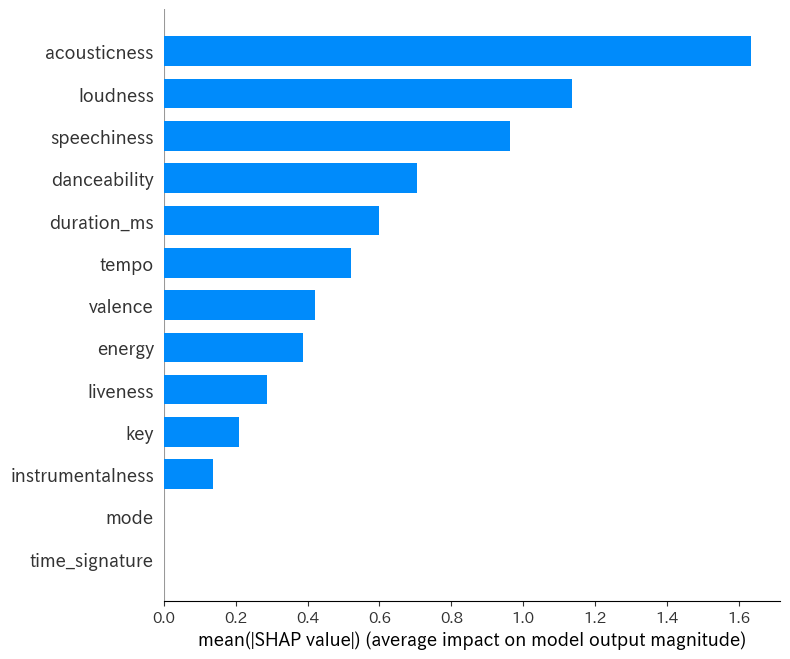

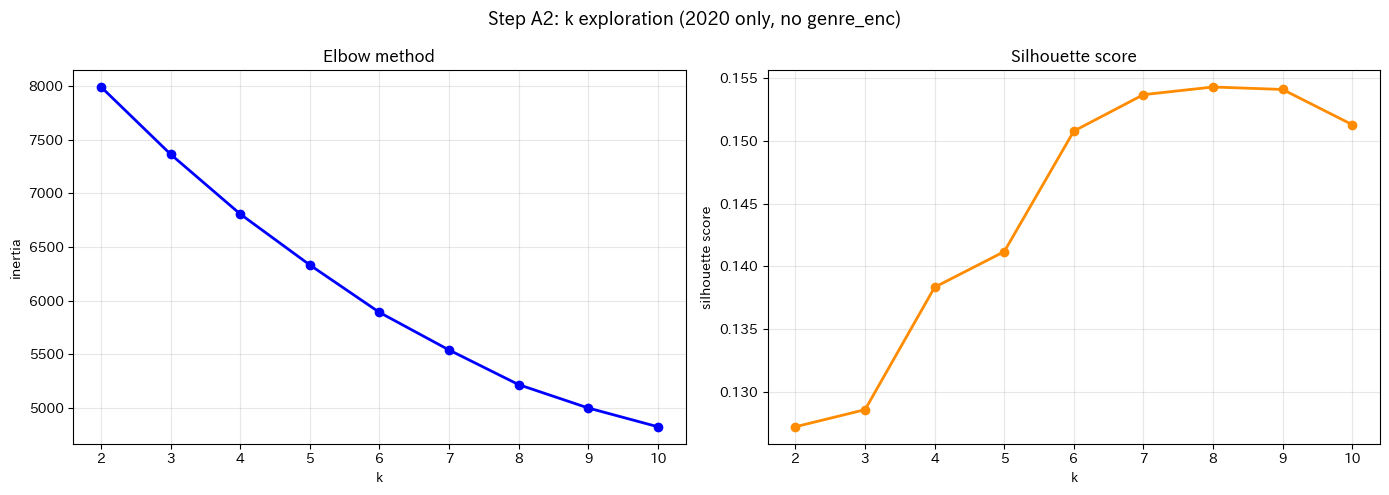

In [139]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scaler_v3 = StandardScaler()
shap_scaled_v3 = scaler_v3.fit_transform(shap_matrix_v3)
print(f"standardized / shape: {shap_scaled_v3.shape}")

inertias_v3 = []
silhouettes_v3 = []
K_range_v3 = range(2, 11)

for k in K_range_v3:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(shap_scaled_v3)
    inertias_v3.append(km.inertia_)
    sil = silhouette_score(shap_scaled_v3, labels_k,
                           sample_size=min(2000, len(shap_scaled_v3)), random_state=42)
    silhouettes_v3.append(sil)
    print(f"  k={k}: inertia={km.inertia_:.1f}, silhouette={sil:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Step A2: k exploration (2020 only, no genre_enc)", fontsize=13, fontweight='bold')

axes[0].plot(list(K_range_v3), inertias_v3, 'b-o', linewidth=2)
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow method")
axes[0].grid(alpha=0.3)

axes[1].plot(list(K_range_v3), silhouettes_v3, 'o-', color='darkorange', linewidth=2)
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette score")
axes[1].set_title("Silhouette score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('phase3_2020_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

#Step3: クラスタリング実行（k=8）

In [140]:
CHOSEN_K_V3 = 8  # 教授指示: クラスタ数を8で固定（2026-11 の打ち合わせ）

km_v3 = KMeans(n_clusters=CHOSEN_K_V3, random_state=42, n_init=10)
cluster_labels_v3 = km_v3.fit_predict(shap_scaled_v3)
df_2020['cluster_v3'] = cluster_labels_v3

chosen_sil_v3 = silhouettes_v3[CHOSEN_K_V3 - 2]
print(f"clustering done / k={CHOSEN_K_V3} (silhouette={chosen_sil_v3:.3f})")
print(f"\ncluster counts:")
print(df_2020['cluster_v3'].value_counts().sort_index().to_string())

print(f"\ncluster overview:")
for k in range(CHOSEN_K_V3):
    mask = df_2020['cluster_v3'] == k
    df_k = df_2020[mask]
    top3_g = df_k['genre'].value_counts().head(3).index.tolist()
    print(f"  cluster {k}: {len(df_k):,} tracks / pop mean={df_k['popularity'].mean():.1f} / {', '.join(top3_g)}")

clustering done / k=8 (silhouette=0.154)

cluster counts:
cluster_v3
0     56
1    165
2    132
3    131
4     57
5     89
6    108
7     82

cluster overview:
  cluster 0: 56 tracks / pop mean=44.6 / k-pop
  cluster 1: 165 tracks / pop mean=49.8 / k-pop
  cluster 2: 132 tracks / pop mean=45.1 / k-pop
  cluster 3: 131 tracks / pop mean=47.2 / k-pop
  cluster 4: 57 tracks / pop mean=41.0 / k-pop
  cluster 5: 89 tracks / pop mean=52.8 / k-pop
  cluster 6: 108 tracks / pop mean=44.9 / k-pop
  cluster 7: 82 tracks / pop mean=44.4 / k-pop


In [141]:
#@title scalingした値を代入
df_2020_sample = df_2020.copy()
df_2020_sample[FEATURE_COLS_V2] = shap_scaled_v3
df_2020_sample

,artist_name,track_name,track_id,popularity,year,genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,cluster_v3
456848,BTS,Dynamite,5QDLhrAOJJdNAmCTJ8xMyW,81,2020,k-pop,-0.902438,1.005474,1.037016,1.202947,0.0,0.134123,2.137019,0.407454,3.243257,0.993794,-0.058501,1.085573,0.0,5
456849,Stray Kids,God’s Menu,4XPXrcpyNr30Km6aPiflJy,74,2020,k-pop,-0.582826,0.796292,0.732222,-0.177010,0.0,0.338378,1.560344,0.323386,-0.387060,1.156103,1.255531,1.398286,0.0,1
456850,BLACKPINK,How You Like That,4SFknyjLcyTLJFPKD2m96o,75,2020,k-pop,-0.834280,0.866241,-0.966086,1.790278,0.0,0.290581,1.345388,-0.788449,1.657965,-0.043037,0.272521,1.011492,0.0,5
456851,TWICE,I CAN'T STOP ME,37ZtpRBkHcaq6hHy0X98zn,73,2020,k-pop,0.660135,0.684301,1.018313,0.067355,0.0,0.173930,0.231421,0.360243,-0.006071,1.012175,1.445000,0.850580,0.0,1
456852,BTS,Life Goes On,5FVbvttjEvQ8r2BgUcJgNg,76,2020,k-pop,1.288491,-0.509497,-0.481108,1.477094,0.0,0.874782,1.679719,0.745307,-1.430596,-0.472486,-2.429729,1.058513,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
457663,POLKADOT STINGRAY,トゲめくスピカ,7dylAisHQrWgpwAQl3o4vb,39,2020,k-pop,1.263839,-0.229308,-1.242786,-0.093716,0.0,0.133571,0.205234,-2.591335,-0.397760,-1.677231,0.087250,-0.436865,0.0,7
457664,ASTRO,ONE&ONLY,5KHxklN5oweX9swnnLY0fV,40,2020,k-pop,0.929351,-2.178680,1.287315,1.175149,0.0,-2.389288,0.237315,0.836123,-0.703072,0.742997,1.200485,-0.777643,0.0,4
457665,Sik-K,The Arrival,7ASnRoq5kwTYggVHBHyTVe,35,2020,k-pop,-1.297362,0.671527,-0.007331,0.968381,0.0,-1.782540,-1.036025,0.498269,2.370935,0.562062,-3.262562,-0.748150,0.0,0
457666,CIX,Rebel,73eV6l2Zmxj7AZul2EeJDc,33,2020,k-pop,0.582896,0.338523,0.666706,-0.860830,0.0,0.235731,0.230491,0.360243,0.429688,0.902869,-0.105659,0.827003,0.0,1


In [142]:
df_2020['cluster_v3'].unique()

array([5, 1, 0, 3, 2, 4, 7, 6], dtype=int32)

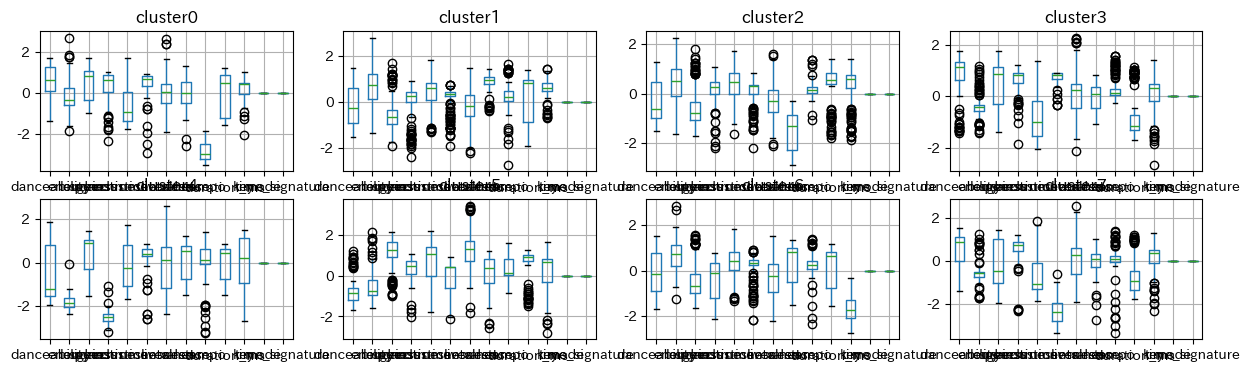

In [143]:
fig, axes = plt.subplots(2,4, figsize=(15,4))
for ax,(i,df) in zip(axes.ravel(), df_2020_sample.groupby('cluster_v3')[FEATURE_COLS_V2]):
  df[FEATURE_COLS_V2].boxplot(ax=ax)
  ax.set_title(f'cluster{i}')
plt.show()

#Step4: 箱ひげ図

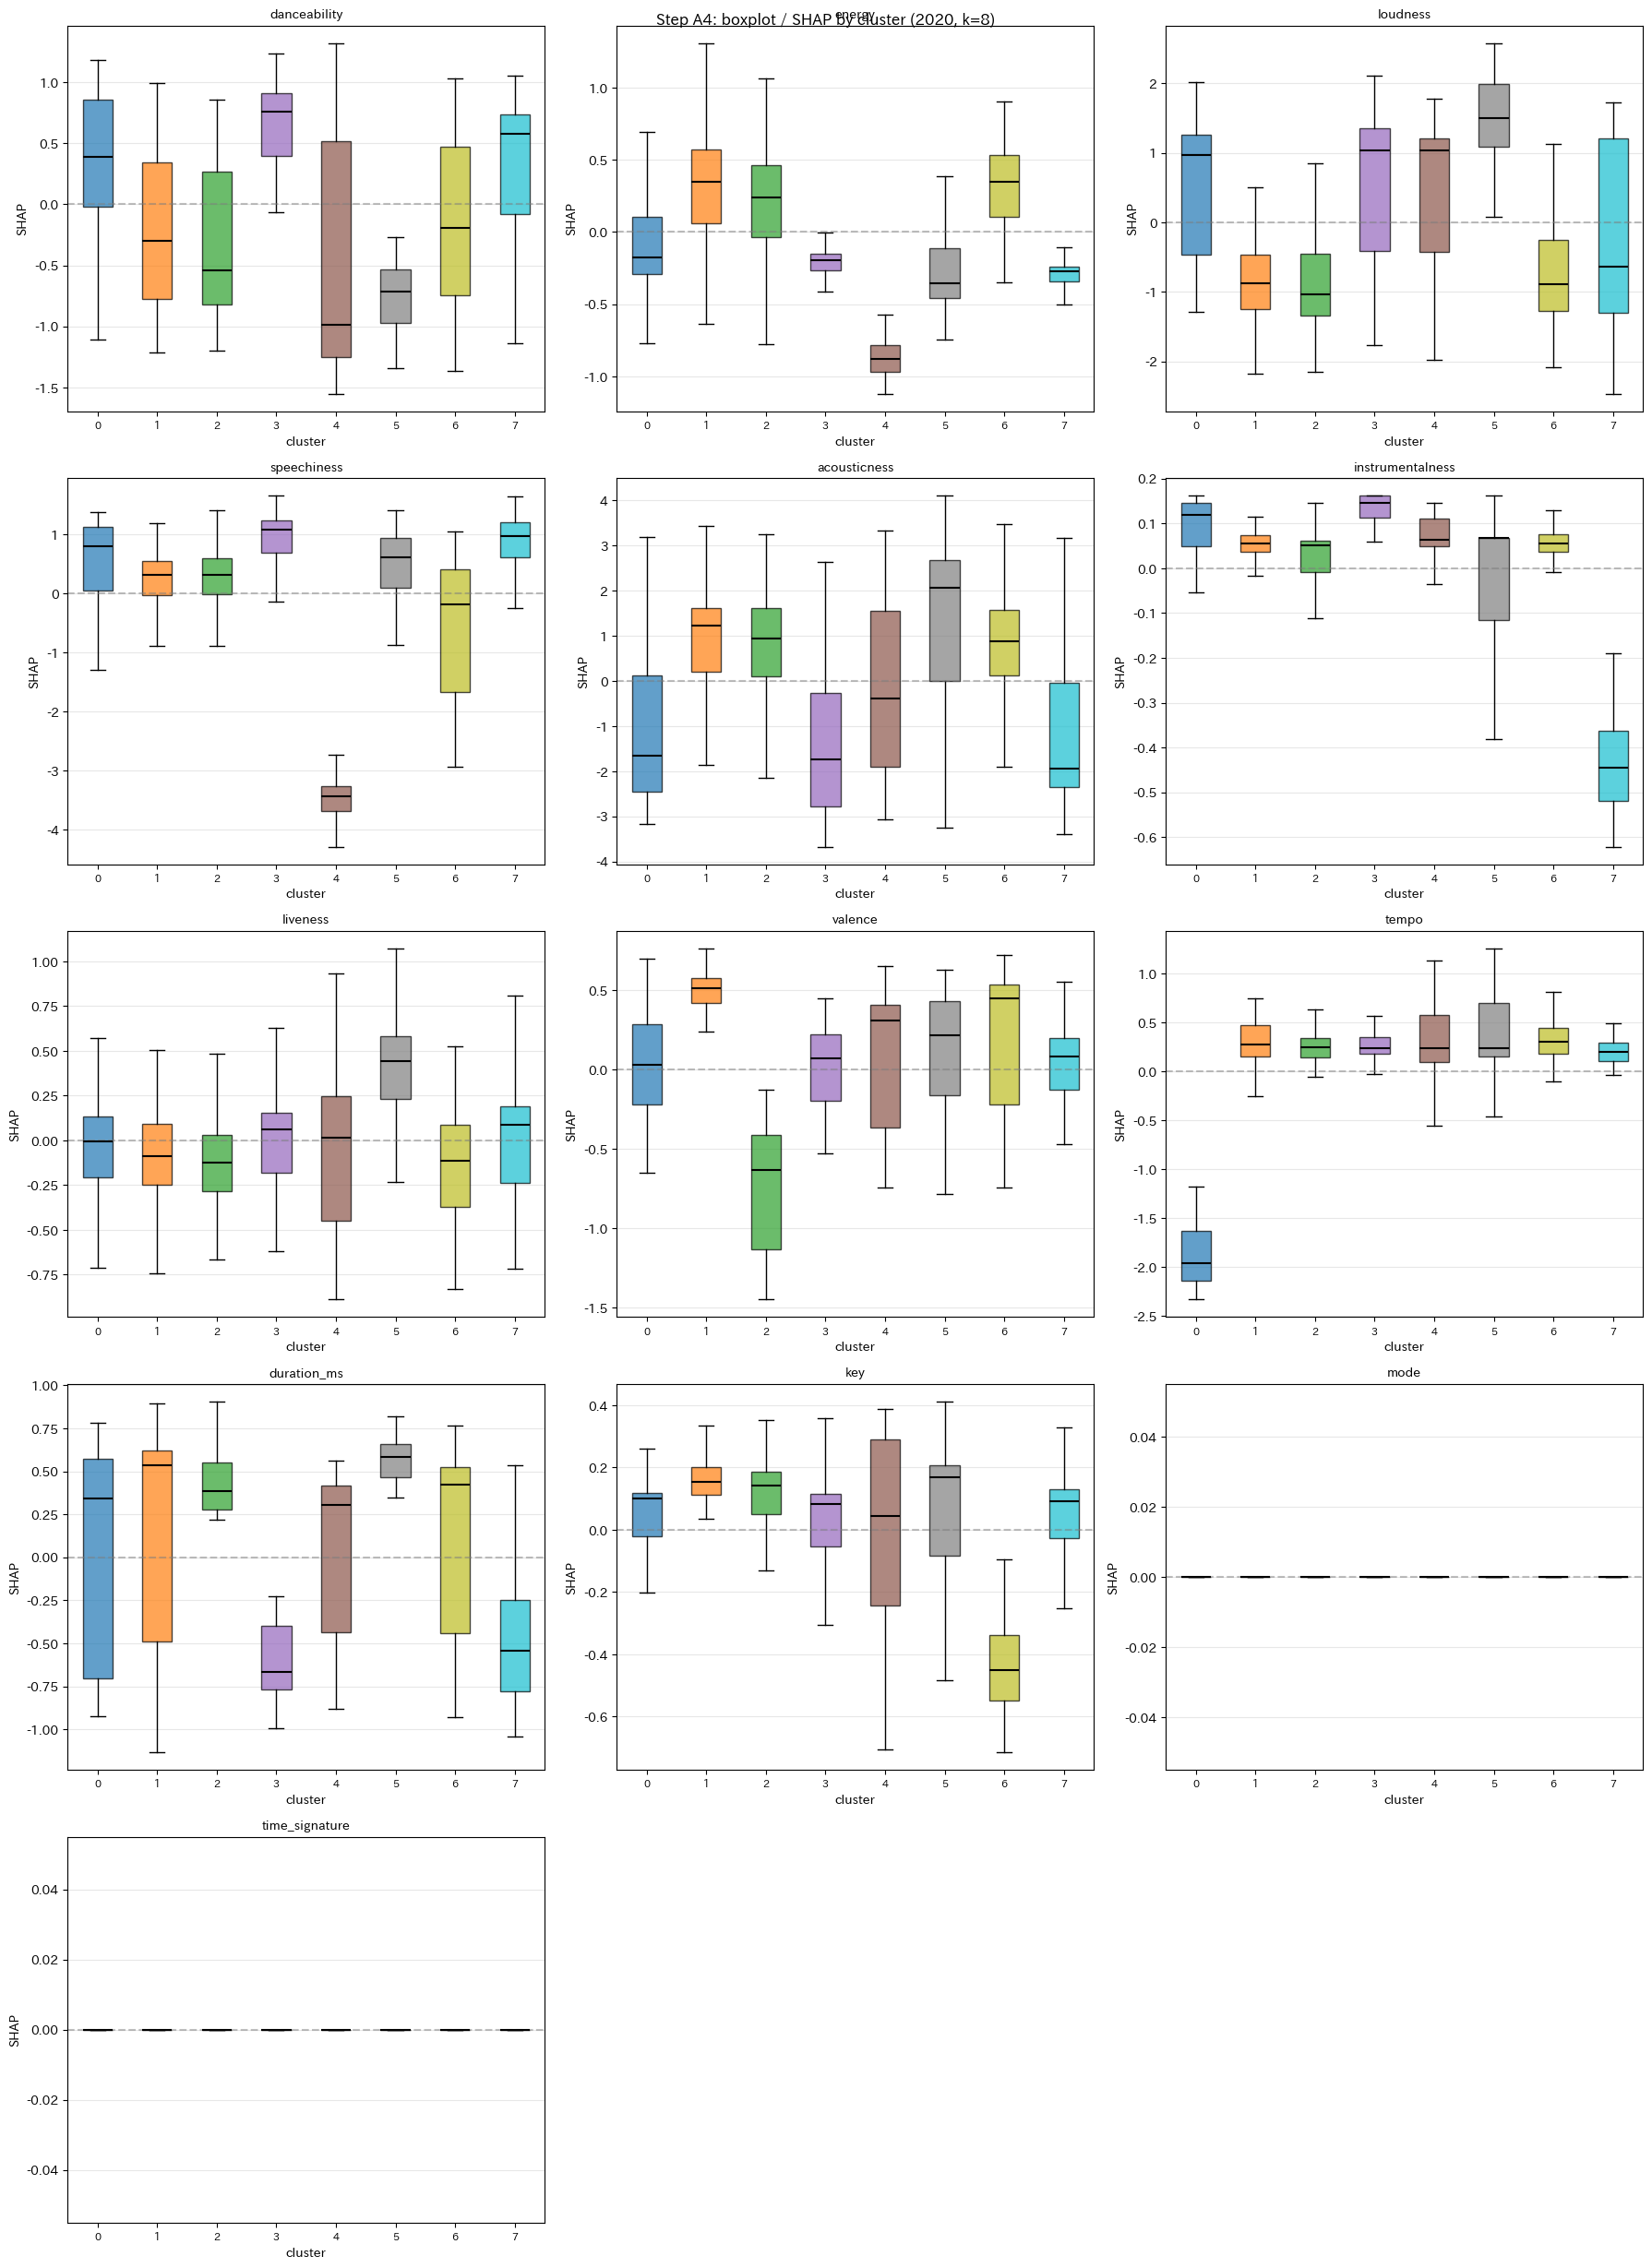

saved: phase3_2020_boxplot.png


In [144]:
#@title plot features
n_cols = 3
n_rows = 5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 25))
fig.suptitle("Step A4: boxplot / SHAP by cluster (2020, k=8)", fontsize=12, fontweight='bold')
colors = plt.cm.tab10(np.linspace(0, 1, CHOSEN_K_V3))
xlabels = [str(i) for i in range(CHOSEN_K_V3)]

for fi, fname in enumerate(FEATURE_COLS_V2):
    r = fi // n_cols
    c = fi % n_cols
    ax = axes[r, c]
    data = [shap_matrix_v3[cluster_labels_v3 == i, fi] for i in range(CHOSEN_K_V3)]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, medianprops=dict(color='black', linewidth=1.5))
    for patch, col in zip(bp['boxes'], colors):
        patch.set_facecolor(col)
        patch.set_alpha(0.7)
    ax.set_title(fname, fontsize=10, fontweight='bold')
    ax.set_xlabel("cluster")
    ax.set_ylabel("SHAP")
    ax.set_xticks(range(1, CHOSEN_K_V3 + 1))
    ax.set_xticklabels(xlabels, fontsize=8)
    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    ax.grid(axis='y', alpha=0.3)

for i in range(len(FEATURE_COLS_V2), n_rows * n_cols):
    axes[i // n_cols][i % n_cols].set_visible(False)

plt.tight_layout()
plt.savefig('phase3_2020_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved: phase3_2020_boxplot.png")

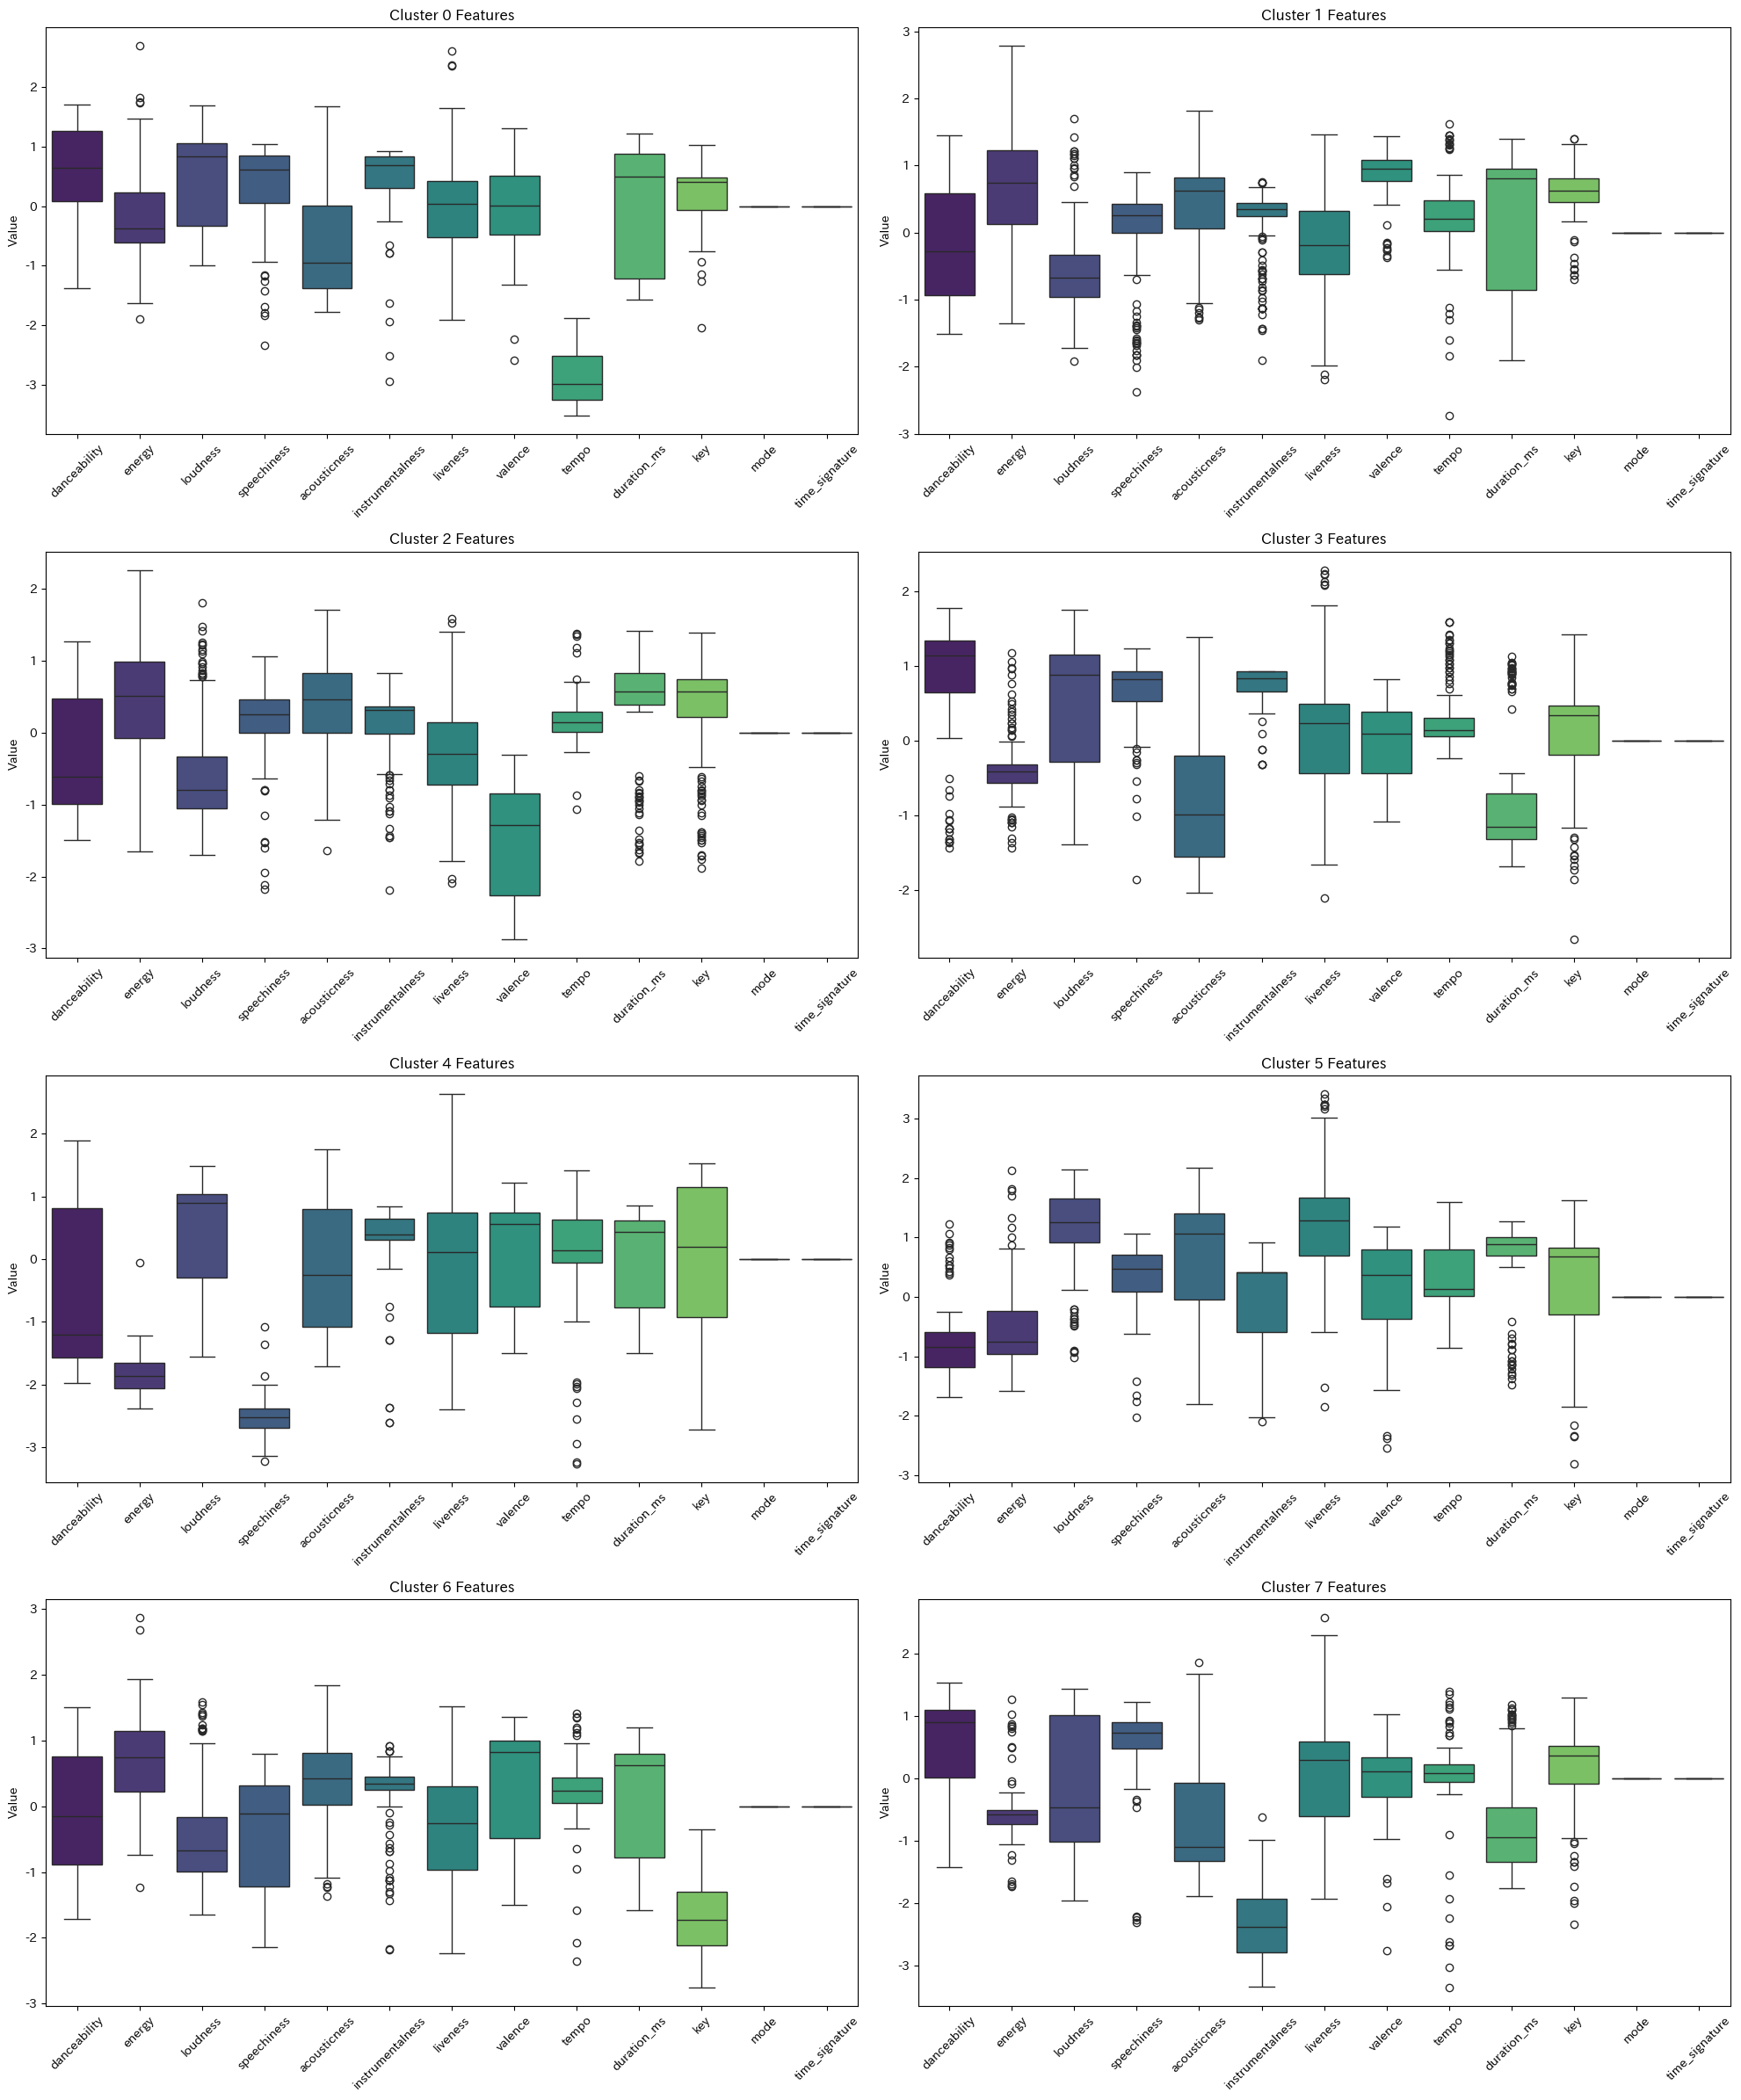

In [145]:
#plot a box plot of all features for each cluster. each box plot should have all features in xticks and plot its value for one cluster
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_clusters = df_2020_sample['cluster_v3'].nunique()
cols = 2
rows = math.ceil(n_clusters / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, 6 * rows))
axes = axes.ravel()

# Melt the dataframe so we can easily plot features on the x-axis
df_melted = df_2020_sample.melt(id_vars=['cluster_v3'], value_vars=FEATURE_COLS_V2, var_name='Feature', value_name='Value')

clusters = sorted(df_2020_sample['cluster_v3'].unique())
for i, cluster_id in enumerate(clusters):
    cluster_data = df_melted[df_melted['cluster_v3'] == cluster_id]
    sns.boxplot(x='Feature', y='Value', data=cluster_data, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Cluster {cluster_id} Features')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


In [146]:
# まとめ出力（実行結果から自動で作る。ジャンルを変えてもそのまま使える）
print("=" * 70)
print(f"Summary: {TARGET_GENRE} / train {TARGET_YEAR} -> test {TEST_YEAR} / k={CHOSEN_K_V3}")
print("=" * 70)

print("\n[Data]")
print(f"  train {TARGET_YEAR}: {len(df_2020):,} tracks / test {TEST_YEAR}: {len(df_2021):,} tracks")
print(f"  popularity {TARGET_YEAR}: mean={df_2020['popularity'].mean():.1f}, std={df_2020['popularity'].std():.2f}")

print("\n[Model: gb2 (iter=100, depth=3, leaf=50, l2=1.0)]")
print(f"  test {TEST_YEAR}: MAE={mean_absolute_error(y_test, gb2_pred):.4f}, R2={r2_score(y_test, gb2_pred):.4f}")

print(f"\n[Clustering on SHAP values of {TARGET_YEAR} tracks]")
print(f"  k = {CHOSEN_K_V3} (silhouette = {chosen_sil_v3:.3f})")

labels_arr = df_2020['cluster_v3'].values
for k in range(CHOSEN_K_V3):
    d_k = df_2020[labels_arr == k]
    mean_shap = shap_matrix_v3[labels_arr == k].mean(axis=0)
    top_i = int(np.argmax(mean_shap))
    bot_i = int(np.argmin(mean_shap))
    line = f"  C{k}: {len(d_k):>4} tracks / pop={d_k['popularity'].mean():.1f}"
    line += f" / SHAP+ {FEATURE_COLS_V2[top_i]}({mean_shap[top_i]:+.2f})"
    line += f" / SHAP- {FEATURE_COLS_V2[bot_i]}({mean_shap[bot_i]:+.2f})"
    print(line)

print("\n" + "=" * 70)

Summary: k-pop / train 2020 -> test 2021 / k=8

[Data]
  train 2020: 820 tracks / test 2021: 873 tracks
  popularity 2020: mean=46.8, std=9.27

[Model: gb2 (iter=100, depth=3, leaf=50, l2=1.0)]
  test 2021: MAE=7.1276, R2=-0.0364

[Clustering on SHAP values of 2020 tracks]
  k = 8 (silhouette = 0.154)
  C0:   56 tracks / pop=44.6 / SHAP+ loudness(+0.55) / SHAP- tempo(-1.87)
  C1:  165 tracks / pop=49.8 / SHAP+ acousticness(+0.86) / SHAP- loudness(-0.74)
  C2:  132 tracks / pop=45.1 / SHAP+ acousticness(+0.76) / SHAP- valence(-0.75)
  C3:  131 tracks / pop=47.2 / SHAP+ speechiness(+0.87) / SHAP- acousticness(-1.52)
  C4:   57 tracks / pop=41.0 / SHAP+ loudness(+0.50) / SHAP- speechiness(-3.38)
  C5:   89 tracks / pop=52.8 / SHAP+ acousticness(+1.34) / SHAP- danceability(-0.61)
  C6:  108 tracks / pop=44.9 / SHAP+ acousticness(+0.79) / SHAP- speechiness(-0.58)
  C7:   82 tracks / pop=44.4 / SHAP+ speechiness(+0.65) / SHAP- acousticness(-1.24)



#Step5: 各クラスタに分けられた曲のタイトル一覧

**打ち合わせメモ**: hip-hop の中で特徴によって違うから、タイトルなどを聞いて違いがわかるか / 各クラスタに分けられた曲のタイトルがわかるか

各クラスタについて次を表示する。

- **特徴量の傾向**: そのクラスタの曲が、ジャンル全体と比べてどの音楽的特徴が高い/低いか（標準化した値の平均）。聴くときに注目するポイントになる
- **代表曲**: クラスタの中心に最も近い曲。そのクラスタらしさが一番よく出ている曲
- **人気曲**: クラスタ内で popularity が高い曲。知っている曲が見つかりやすい
- **主なアーティスト**: 1人のアーティストの曲ばかりなら、クラスタは「音の違い」ではなく「アーティストの違い」を拾っている可能性がある



In [147]:
# Step5: 各クラスタに分けられた曲のタイトル一覧
# 必要な変数: df_2020, shap_scaled_v3, km_v3, CHOSEN_K_V3, FEATURE_COLS_V2, TARGET_GENRE, TARGET_YEAR

N_SHOW = 5

df_tracks = df_2020.copy()
df_tracks['spotify_url'] = 'https://open.spotify.com/track/' + df_tracks['track_id'].astype(str)

# クラスタ中心からの距離（小さいほど、そのクラスタらしい曲）
labels_arr = df_tracks['cluster_v3'].values
centers = km_v3.cluster_centers_
df_tracks['dist_to_center'] = np.linalg.norm(shap_scaled_v3 - centers[labels_arr], axis=1)

# 音楽的特徴をジャンル内で標準化（0 = ジャンル平均、+1 = 平均より1標準偏差高い）
feat_z = (df_tracks[FEATURE_COLS_V2] - df_tracks[FEATURE_COLS_V2].mean()) / df_tracks[FEATURE_COLS_V2].std()


def print_track(row):
    title = str(row['track_name'])[:38].ljust(40)
    artist = str(row['artist_name'])[:22].ljust(24)
    pop = str(int(row['popularity'])).rjust(3)
    print("    " + title + artist + pop + "  " + row['spotify_url'])


for k in range(CHOSEN_K_V3):
    mask = labels_arr == k
    d_k = df_tracks[mask]

    print("=" * 110)
    print(f"cluster {k}: {len(d_k)} tracks / popularity mean = {d_k['popularity'].mean():.1f} / artists = {d_k['artist_name'].nunique()}")

    # 特徴量の傾向（ジャンル平均との差が大きい順に3つ）
    z_mean = feat_z[mask].mean().sort_values()
    high = z_mean.tail(3)[::-1]
    low = z_mean.head(3)
    print("  high: " + ", ".join(f"{f}({v:+.2f})" for f, v in high.items()))
    print("  low : " + ", ".join(f"{f}({v:+.2f})" for f, v in low.items()))

    # 主なアーティスト
    top_art = d_k['artist_name'].value_counts().head(3)
    print("  top artists: " + ", ".join(f"{a} ({n})" for a, n in top_art.items()))

    print("  --- representative tracks (closest to cluster center) ---")
    for _, row in d_k.nsmallest(N_SHOW, 'dist_to_center').iterrows():
        print_track(row)

    print("  --- most popular tracks ---")
    for _, row in d_k.nlargest(N_SHOW, 'popularity').iterrows():
        print_track(row)

print("=" * 110)

# 全曲の一覧をCSVに保存（Excelで文字化けしないよう utf-8-sig）
out_cols = ['cluster_v3', 'track_name', 'artist_name', 'popularity', 'dist_to_center', 'spotify_url'] + FEATURE_COLS_V2
csv_name = f"clusters_{TARGET_GENRE}_{TARGET_YEAR}_tracks.csv"
df_tracks.sort_values(['cluster_v3', 'dist_to_center'])[out_cols].to_csv(csv_name, index=False, encoding='utf-8-sig')
print("saved:", csv_name)

cluster 0: 56 tracks / popularity mean = 44.6 / artists = 43
  high: acousticness(+0.61), key(+0.09), mode(+0.05)
  low : tempo(-1.56), energy(-0.52), danceability(-0.43)
  top artists: BTS (3), GOT7 (3), Junggigo (2)
  --- representative tracks (closest to cluster center) ---
    Mayday (feat. 조이)                       Crush                    52  https://open.spotify.com/track/37cXQzQaHR7zMk8G360Vke
    Let Me Go (with TAEYEON)                Crush                    45  https://open.spotify.com/track/0W1BHowUDWND1AIQU6nUbD
    Thank You, Sorry                        GOT7                     38  https://open.spotify.com/track/72CFnNVdYSWvH70PkovdM2
    Amusement Park                          BAEKHYUN                 55  https://open.spotify.com/track/1TUkEXQrskATO9SoB4QMUN
    friend to lover                         Standing Egg             48  https://open.spotify.com/track/7un5FM27KmkEMpsPQ2T062
  --- most popular tracks ---
    Life Goes On                            BTS          

#Step6: 係数分析（Ridge回帰）

**打ち合わせメモ**: 係数分析

gb2（決定木のモデル）には係数がないので、係数分析には**線形回帰（Ridge回帰）**を使う。

- 学習 = 2020年、評価 = 2021年（gb2 と同じ条件）
- 特徴量は標準化してから学習する。そのため係数は「**その特徴が1標準偏差増えたとき、人気度が何ポイント変わるか**」と読める。特徴量どうしで大きさを比べられる
- 係数の信頼性を見るため、学習データを1000回リサンプリング（ブートストラップ）して **95%信頼区間**を出す。区間が0をまたがない係数だけを「有意」とする
- gb2 の SHAP 重要度（平均|SHAP|）と並べて、2つのモデルで重要とされる特徴が一致するかを確認する

 有意な係数があっても、R² が小さければ人気度全体への影響は小さい。
「その特徴が人気度を決めている」ではなく「わずかに傾向がある」

Step6: coefficient analysis (k-pop, train 2020 -> test 2021)
  ridge: MAE=7.0311, R2=-0.0010
  gb2  : MAE=7.1276, R2=-0.0364

coef = popularity change per +1 SD of the feature (sorted by |coef|)
                   coef  ci_low  ci_high  mean_abs_shap_gb2  significant
acousticness     -1.973  -2.831   -1.049              1.553         True
speechiness      -1.455  -2.135   -0.792              1.003         True
danceability     -0.677  -1.398    0.014              0.677        False
tempo             0.494  -0.126    1.163              0.496        False
mode             -0.309  -0.952    0.279              0.000        False
energy           -0.307  -1.408    0.778              0.389        False
valence          -0.249  -1.000    0.548              0.429        False
key               0.221  -0.394    0.876              0.212        False
liveness         -0.182  -0.825    0.450              0.280        False
instrumentalness -0.118  -0.536    0.260              0.136        False
ti

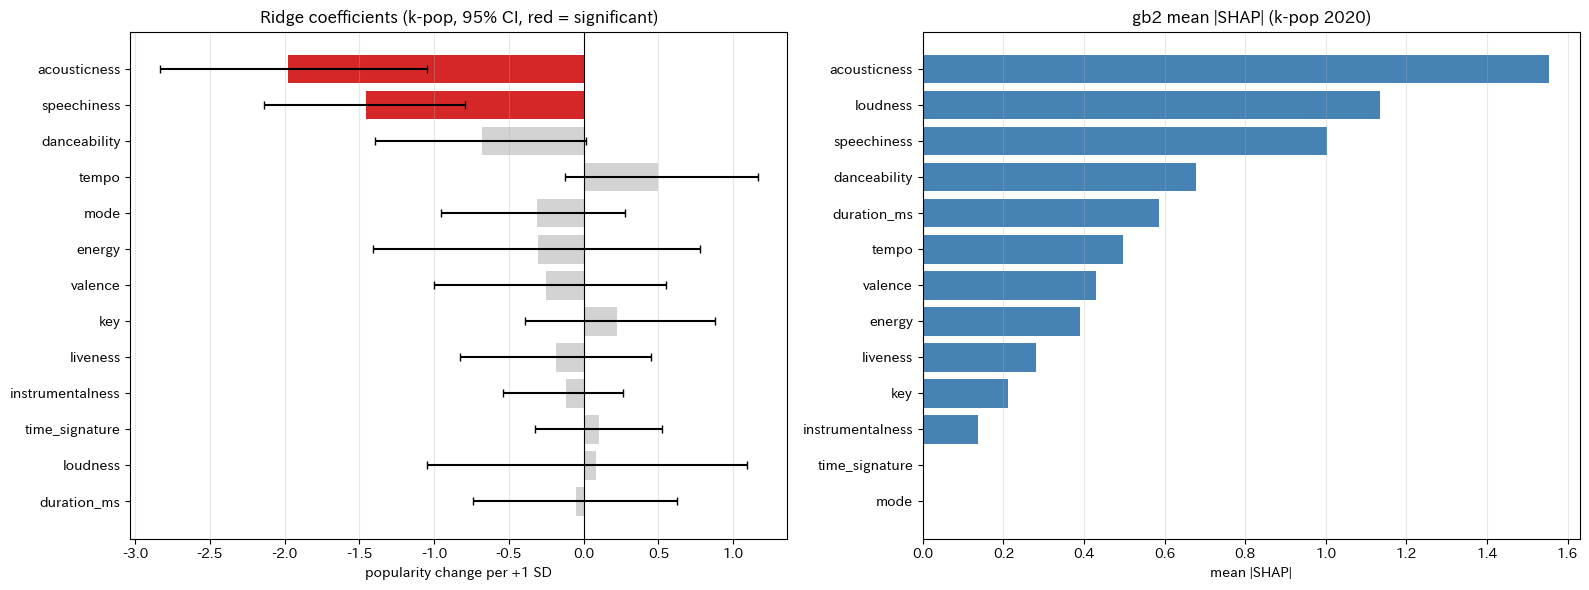


significant features: acousticness(-1.97), speechiness(-1.45)


In [148]:
# Step6: 係数分析（Ridge回帰 + ブートストラップ95%信頼区間）
# 必要な変数: X2_train, y_train, X2_test, y_test, gb2_pred, shap_matrix_v3, FEATURE_COLS_V2, TARGET_GENRE

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

RIDGE_ALPHA = 10.0
N_BOOT = 1000

ridge = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
ridge.fit(X2_train, y_train)
ridge_pred = ridge.predict(X2_test)

print(f"Step6: coefficient analysis ({TARGET_GENRE}, train {TARGET_YEAR} -> test {TEST_YEAR})")
print("=" * 70)
print(f"  ridge: MAE={mean_absolute_error(y_test, ridge_pred):.4f}, R2={r2_score(y_test, ridge_pred):.4f}")
print(f"  gb2  : MAE={mean_absolute_error(y_test, gb2_pred):.4f}, R2={r2_score(y_test, gb2_pred):.4f}")

coef = pd.Series(ridge.named_steps['ridge'].coef_, index=FEATURE_COLS_V2)

# 学習データをリサンプリングして係数のばらつきを見る
rng_c = np.random.default_rng(0)
Xv = X2_train.values
yv = y_train.values
boot = np.zeros((N_BOOT, len(FEATURE_COLS_V2)))
for b in range(N_BOOT):
    bi = rng_c.integers(0, len(yv), len(yv))
    m = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
    m.fit(Xv[bi], yv[bi])
    boot[b] = m.named_steps['ridge'].coef_

coef_table = pd.DataFrame({
    'coef': coef,
    'ci_low': np.percentile(boot, 2.5, axis=0),
    'ci_high': np.percentile(boot, 97.5, axis=0),
    'mean_abs_shap_gb2': np.abs(shap_matrix_v3).mean(axis=0),
})
coef_table['significant'] = (coef_table['ci_low'] > 0) | (coef_table['ci_high'] < 0)
coef_table = coef_table.reindex(coef_table['coef'].abs().sort_values(ascending=False).index)

print()
print("coef = popularity change per +1 SD of the feature (sorted by |coef|)")
print(coef_table.round(3).to_string())

# 図: 左 = Ridge係数と95%信頼区間（赤 = 有意）、右 = gb2 の SHAP 重要度
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

t = coef_table.iloc[::-1]
bar_colors = ['tab:red' if s else 'lightgray' for s in t['significant']]
err_low = np.clip((t['coef'] - t['ci_low']).values, 0, None)
err_high = np.clip((t['ci_high'] - t['coef']).values, 0, None)
axes[0].barh(t.index, t['coef'], xerr=[err_low, err_high], color=bar_colors, capsize=3)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title(f"Ridge coefficients ({TARGET_GENRE}, 95% CI, red = significant)")
axes[0].set_xlabel("popularity change per +1 SD")
axes[0].grid(axis='x', alpha=0.3)

t2 = coef_table.sort_values('mean_abs_shap_gb2')
axes[1].barh(t2.index, t2['mean_abs_shap_gb2'], color='steelblue')
axes[1].set_title(f"gb2 mean |SHAP| ({TARGET_GENRE} {TARGET_YEAR})")
axes[1].set_xlabel("mean |SHAP|")
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(f'step6_coef_{TARGET_GENRE}.png', dpi=150, bbox_inches='tight')
plt.show()

sig = coef_table[coef_table['significant']]
print()
print("significant features:", ", ".join(f"{f}({v:+.2f})" for f, v in sig['coef'].items()) if len(sig) > 0 else "none")

#Step7: 知っている楽曲を探す

**打ち合わせメモ**: 次の進め方の指標として、自分の知っている楽曲を探す

有名アーティストの名前でデータを検索し、**見つかった曲がどのクラスタに入っているか**を表示する。

- `KNOWN_ARTISTS` に知っているアーティストを足して再実行してよい（洋楽・K-POP どちらも入れてある）
- `SEARCH_WORD` に文字を入れると、曲名とアーティスト名の部分一致で検索できる（例: `"Drake"`、`"Dynamite"`）
- クラスタごとに「知っている曲が何曲あるか」も出す。知っている曲が1曲もないクラスタは、聴いて確かめるのが難しい

`TARGET_GENRE` を `k-pop` に変えて上から実行し直せば、K-POP でも同じことができる。

In [149]:
# Step7: 知っている楽曲を探す
# 必要な変数: df_tracks（Step5で作成。無ければ df_2020）, CHOSEN_K_V3

import re

# 知っているアーティスト（自由に足してよい）
KNOWN_ARTISTS = [
    # 洋楽ヒップホップ・ポップ
    'Drake', 'Eminem', 'Travis Scott', 'Post Malone', 'Kanye West', 'Nicki Minaj',
    'Cardi B', 'Megan Thee Stallion', 'DaBaby', 'Lil Nas X', 'Doja Cat', 'Juice WRLD',
    'XXXTENTACION', 'Machine Gun Kelly', 'The Kid LAROI', 'Jack Harlow', '21 Savage',
    'Lil Baby', 'Future', 'Playboi Carti', 'Tyler, The Creator', 'Kendrick Lamar',
    'J. Cole', 'Pop Smoke', 'Roddy Ricch', 'Bad Bunny', 'Daddy Yankee', 'Justin Bieber',
    'The Weeknd', 'Ariana Grande', 'Dua Lipa', 'Billie Eilish', 'Bruno Mars',
    # K-POP
    'BTS', 'BLACKPINK', 'TWICE', 'Stray Kids', 'SEVENTEEN', 'NCT', 'TXT',
    'TOMORROW X TOGETHER', 'ITZY', 'IU', 'EXO', 'Red Velvet', 'aespa', 'ENHYPEN',
    'MONSTA X', 'GOT7', 'NiziU', 'IVE', 'LE SSERAFIM', 'NewJeans',
]

SEARCH_WORD = "Dynamite"  # 例: "Drake" / "Dynamite" / "Butter"

# Step5 を実行済みなら df_tracks を使う。未実行なら df_2020 から作る
try:
    base = df_tracks.copy()
except NameError:
    base = df_2020.copy()
    base['spotify_url'] = 'https://open.spotify.com/track/' + base['track_id'].astype(str)


def show_track(row, show_cluster=True):
    title = str(row['track_name'])[:38].ljust(40)
    artist = str(row['artist_name'])[:22].ljust(24)
    pop = str(int(row['popularity'])).rjust(3)
    cl = f"  C{int(row['cluster_v3'])}" if show_cluster else ""
    print("    " + title + artist + pop + cl + "  " + row['spotify_url'])


pattern = "|".join(re.escape(a) for a in KNOWN_ARTISTS)
hits = base[base['artist_name'].str.contains(pattern, case=False, na=False)].copy()

print(f"Step7: known tracks in {TARGET_GENRE} {TARGET_YEAR}")
print("=" * 100)
print(f"total tracks: {len(base)} / matched by KNOWN_ARTISTS: {len(hits)} ({len(hits)/len(base)*100:.1f}%)")

print()
print("--- most popular known tracks (top 20) ---")
for _, row in hits.nlargest(20, 'popularity').iterrows():
    show_track(row)

print()
print("--- known tracks by cluster ---")
for k in range(CHOSEN_K_V3):
    size_k = int((base['cluster_v3'] == k).sum())
    hk = hits[hits['cluster_v3'] == k].sort_values('popularity', ascending=False)
    print("=" * 100)
    print(f"cluster {k}: {len(hk)} known tracks / cluster size {size_k}")
    if len(hk) == 0:
        print("    (no known tracks)")
    for _, row in hk.head(8).iterrows():
        show_track(row, show_cluster=False)

# 任意のキーワード検索
if SEARCH_WORD:
    m_title = base['track_name'].str.contains(SEARCH_WORD, case=False, na=False)
    m_artist = base['artist_name'].str.contains(SEARCH_WORD, case=False, na=False)
    found = base[m_title | m_artist].sort_values('popularity', ascending=False)
    print()
    print("=" * 100)
    print(f"search '{SEARCH_WORD}': {len(found)} tracks")
    for _, row in found.head(20).iterrows():
        show_track(row)

Step7: known tracks in k-pop 2020
total tracks: 820 / matched by KNOWN_ARTISTS: 243 (29.6%)

--- most popular known tracks (top 20) ---
    Dynamite                                BTS                      81  C5  https://open.spotify.com/track/5QDLhrAOJJdNAmCTJ8xMyW
    Life Goes On                            BTS                      76  C0  https://open.spotify.com/track/5FVbvttjEvQ8r2BgUcJgNg
    How You Like That                       BLACKPINK                75  C5  https://open.spotify.com/track/4SFknyjLcyTLJFPKD2m96o
    God’s Menu                              Stray Kids               74  C1  https://open.spotify.com/track/4XPXrcpyNr30Km6aPiflJy
    Filter                                  BTS                      74  C5  https://open.spotify.com/track/4bZZVcgWWMWPBwzTTp642w
    I CAN'T STOP ME                         TWICE                    73  C1  https://open.spotify.com/track/37ZtpRBkHcaq6hHy0X98zn
    Back Door                               Stray Kids               72  C1  h

#Step8: 知っている3曲の特徴量とグラフ

2020年前後に流行し、洋楽に詳しくなくても知られている3曲をデータから取り出して比較する。

| 曲 | アーティスト | ジャンル | 年 | 人気度 |
|----|------------|---------|----|-------|
| Blinding Lights | The Weeknd | pop | 2020 | 90 |
| Dance Monkey | Tones And I | pop | 2019 | 76 |
| Dynamite | BTS | k-pop | 2020 | 81 |

**グラフの読み方**: 縦軸・各軸の値は **z スコア**（その曲と同じジャンル・同じ年の平均を 0、ばらつき1つ分を 1 とした値）。
0 より大きければ「同ジャンル・同年の平均より高い」、小さければ「低い」。
ジャンルが違う3曲を同じ土俵で比べるため、生の値ではなく各ジャンル内での位置に直している。


Blinding Lights: The Weeknd / pop 2020 / popularity=90 / baseline n=318
Dance Monkey: Tones And I / pop 2019 / popularity=76 / baseline n=318
Dynamite: BTS / k-pop 2020 / popularity=81 / baseline n=820

=== raw feature values ===
                  Blinding Lights  Dance Monkey    Dynamite
danceability                0.514         0.824       0.746
energy                      0.730         0.588       0.765
loudness                   -5.934        -6.400      -4.410
speechiness                 0.060         0.092       0.099
acousticness                0.001         0.692       0.011
instrumentalness            0.000         0.000       0.000
liveness                    0.090         0.149       0.094
valence                     0.334         0.513       0.737
tempo                     171.005        98.027     114.044
duration_ms            200040.000    209438.000  199054.000
key                         1.000         6.000       6.000
mode                        1.000         0.000   

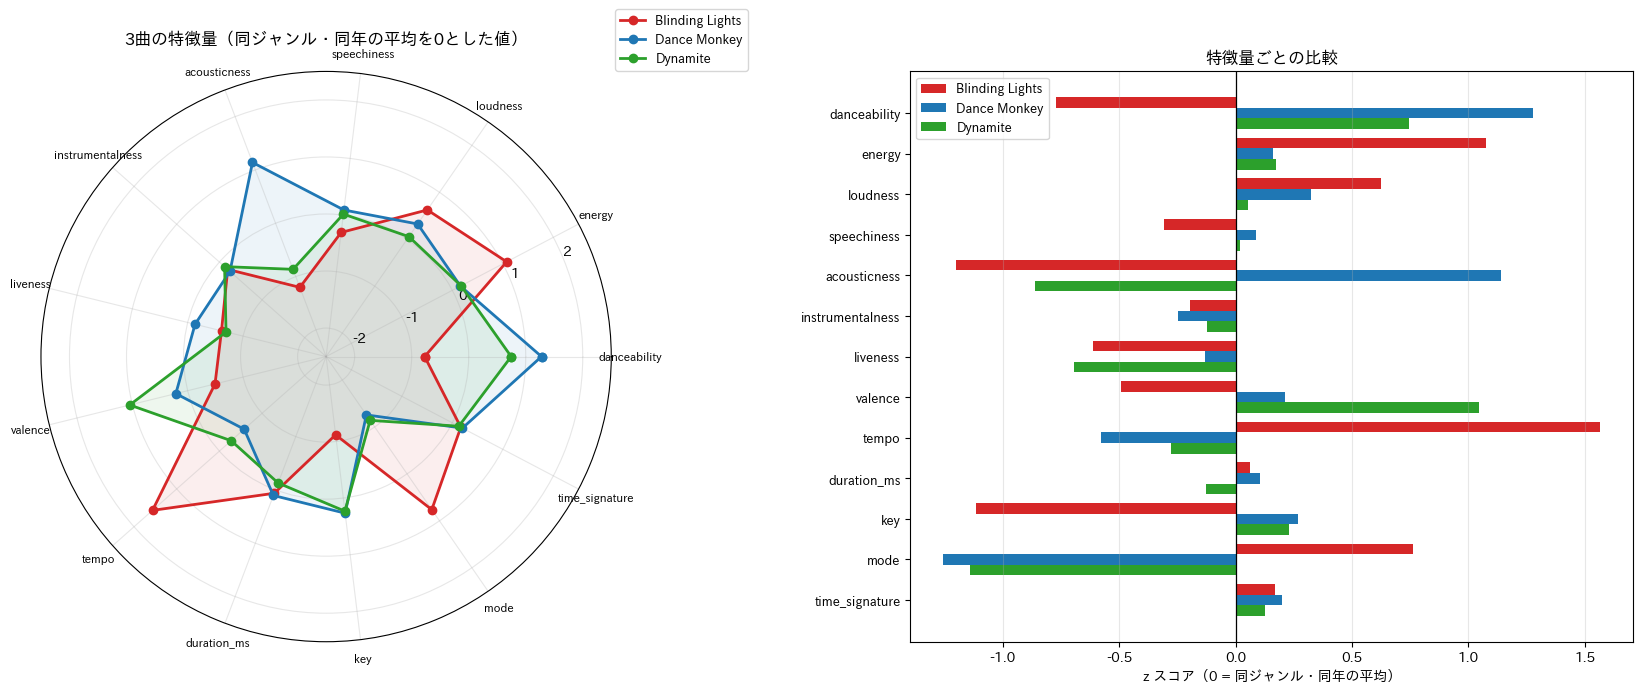

saved: step8_known_tracks.png


In [150]:
# Step8: 知っている3曲の特徴量とグラフ
# 必要な変数: df_clean, FEATURE_COLS_V2（cell-2〜8, cell-10）

KNOWN_TRACKS = [
    ('0VjIjW4GlUZAMYd2vXMi3b', 'Blinding Lights'),
    ('2XU0oxnq2qxCpomAAuJY8K', 'Dance Monkey'),
    ('5QDLhrAOJJdNAmCTJ8xMyW', 'Dynamite'),
]

items = []
for tid, label in KNOWN_TRACKS:
    hit = df_clean[df_clean['track_id'] == tid]
    if len(hit) == 0:
        print("not found:", label)
        continue
    row = hit.iloc[0]
    # 同じジャンル・同じ年の曲を基準にする
    base = df_clean[(df_clean['genre'] == row['genre']) & (df_clean['year'] == row['year'])]
    z = (row[FEATURE_COLS_V2].astype(float) - base[FEATURE_COLS_V2].mean()) / base[FEATURE_COLS_V2].std()
    items.append({'label': label, 'row': row, 'z': z, 'n': len(base)})
    print(f"{label}: {row['artist_name']} / {row['genre']} {row['year']} / popularity={row['popularity']} / baseline n={len(base)}")

# 表1: 生の特徴量
raw_table = pd.DataFrame({it['label']: it['row'][FEATURE_COLS_V2].astype(float) for it in items})
print()
print("=== raw feature values ===")
print(raw_table.round(3).to_string())

# 表2: z スコア（同ジャンル・同年の平均との差）
z_table = pd.DataFrame({it['label']: it['z'] for it in items})
print()
print("=== z-score (0 = average of same genre & year) ===")
print(z_table.round(2).to_string())

# グラフ: 左=レーダーチャート / 右=横棒グラフ
labels = FEATURE_COLS_V2
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]
colors = ['tab:red', 'tab:blue', 'tab:green']

fig = plt.figure(figsize=(17, 7))

ax1 = fig.add_subplot(1, 2, 1, polar=True)
for i, it in enumerate(items):
    vals = it['z'].tolist()
    vals += vals[:1]
    ax1.plot(angles, vals, 'o-', linewidth=2, color=colors[i], label=it['label'])
    ax1.fill(angles, vals, alpha=0.08, color=colors[i])
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(labels, fontsize=8)
ax1.set_ylim(-2.5, 2.5)
ax1.set_title("3曲の特徴量（同ジャンル・同年の平均を0とした値）", fontsize=12, fontweight='bold', pad=20)
ax1.legend(loc='upper right', bbox_to_anchor=(1.25, 1.12), fontsize=9)
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(1, 2, 2)
y = np.arange(len(labels))
h = 0.26
for i, it in enumerate(items):
    ax2.barh(y + (i - 1) * h, it['z'].values, height=h, color=colors[i], label=it['label'])
ax2.set_yticks(y)
ax2.set_yticklabels(labels, fontsize=9)
ax2.axvline(0, color='black', linewidth=0.9)
ax2.set_xlabel("z スコア（0 = 同ジャンル・同年の平均）")
ax2.set_title("特徴量ごとの比較", fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(axis='x', alpha=0.3)
ax2.invert_yaxis()

plt.tight_layout()
plt.savefig('step8_known_tracks.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved: step8_known_tracks.png")


#Step9: Dynamite（原曲＋リミックス9種）がどのクラスタに入ったか

**目的**: 同じ曲・同じメロディで、アレンジだけが違う10曲がどのクラスタに入ったかを確かめる。

- **別々のクラスタに分かれる** → クラスタは「音の作り（アレンジ）」の違いを捉えている
- **全部同じクラスタ** → クラスタは音の違いをあまり捉えていない

特徴量は「k-pop 2020年の平均を0、ばらつき1つ分を1とした値（z スコア）」で表示する。
原曲と Acoustic Remix・EDM Remix を聴き比べたときの印象と、この表の値が合っているかも確認する（次回の「聴感と特徴量の比較」につなげる）。


Dynamite versions: 10 tracks / clusters used: [1, 2, 3, 5, 6]

version               pop  cl  dancea  energy  valenc  acoust  loudne   tempo  speech
-------------------------------------------------------------------------------------
Original               81  C5   +0.75   +0.17   +1.05   -0.86   +0.06   -0.28   +0.02
Tropical Remix         52  C6   +0.61   +0.96   +0.46   -0.79   +0.56   -0.28   -0.36
Acoustic Remix         49  C6   +0.00   +0.92   +0.23   -0.82   -0.28   -0.28   +1.22
EDM Remix              47  C5   +0.42   +0.61   -1.07   -0.90   -0.09   +0.06   -0.44
Slow Jam Remix         46  C3   -0.02   -0.32   +0.02   +0.57   +0.32   -0.28   -0.68
Poolside Remix         46  C6   +0.25   +0.85   -0.63   -0.87   -0.15   +0.10   +0.52
Holiday Remix          45  C1   +0.17   +0.83   +0.33   -0.83   +1.32   -0.28   -0.24
Retro Remix            45  C2   -0.07   +1.08   +1.24   -0.64   +1.14   -0.28   +0.58
Bedroom Remix          45  C1   +0.83   +0.05   +0.99   -0.65   +0.58   -0.46

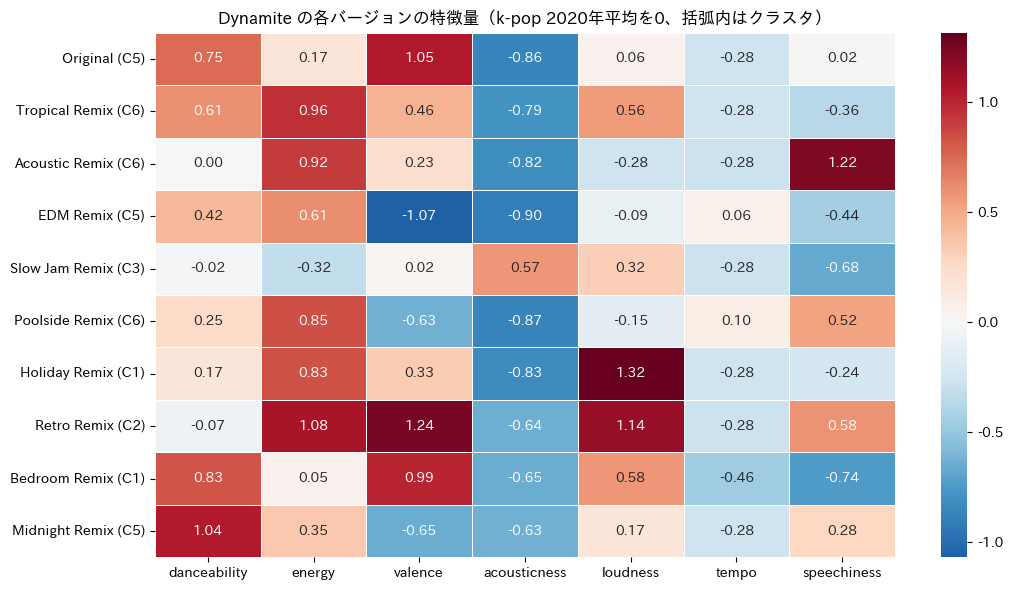

saved: step9_dynamite_versions.png


In [151]:
# Step9: Dynamite（原曲＋リミックス9種）のクラスタと特徴量
# 必要な変数: df_2020（cluster_v3 付き）, FEATURE_COLS_V2

SHOW_FEATS = ['danceability', 'energy', 'valence', 'acousticness', 'loudness', 'tempo', 'speechiness']

is_dyn = df_2020['track_name'].str.contains('Dynamite', case=False, na=False) & (df_2020['artist_name'] == 'BTS')
dyn = df_2020[is_dyn].copy()

# k-pop 2020年の平均を0とした z スコア
feat_mean = df_2020[FEATURE_COLS_V2].mean()
feat_std = df_2020[FEATURE_COLS_V2].std()
for f in SHOW_FEATS:
    dyn[f + '_z'] = (dyn[f] - feat_mean[f]) / feat_std[f]

dyn['version'] = dyn['track_name'].str.replace('Dynamite - ', '', regex=False).str.replace('Dynamite', 'Original', regex=False)
dyn = dyn.sort_values('popularity', ascending=False)

print(f"Dynamite versions: {len(dyn)} tracks / clusters used: {sorted(dyn['cluster_v3'].unique().tolist())}")
print()

head = "version".ljust(20) + "pop".rjust(5) + "  cl" + "".join(f[:6].rjust(8) for f in SHOW_FEATS)
print(head)
print("-" * len(head))
for _, r in dyn.iterrows():
    line = str(r['version'])[:18].ljust(20) + str(int(r['popularity'])).rjust(5) + ("C" + str(int(r['cluster_v3']))).rjust(4)
    line += "".join(f"{r[f + '_z']:+.2f}".rjust(8) for f in SHOW_FEATS)
    print(line)
print("values are z-scores (0 = k-pop 2020 average)")

# クラスタごとの内訳
print()
print("cluster breakdown:")
for cl, grp in dyn.groupby('cluster_v3'):
    print(f"  C{int(cl)}: {len(grp)} versions -> " + ", ".join(grp['version'].tolist()))

# 図: バージョンごとの特徴量（z スコア）。行ラベルの括弧内はクラスタ番号
plot_df = dyn.set_index(dyn['version'] + ' (C' + dyn['cluster_v3'].astype(int).astype(str) + ')')[[f + '_z' for f in SHOW_FEATS]]
plot_df.columns = SHOW_FEATS
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(plot_df, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5, ax=ax)
ax.set_title("Dynamite の各バージョンの特徴量（k-pop 2020年平均を0、括弧内はクラスタ）", fontsize=12, fontweight='bold')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('step9_dynamite_versions.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved: step9_dynamite_versions.png")


#Step10: Dynamite の　force plot

他の曲（Dynamite）などでも shap.initjs の赤と青の図を作ってみる

- **赤** = 人気度の予測を押し上げた特徴、**青** = 押し下げた特徴。棒が長いほど影響が大きい
- 左端の **base value** は k-pop 2020年の平均的な予測値。そこに各特徴の影響が足し引きされて、その曲の予測値（太字）になる
- 原曲と、性格の違うリミックス（Acoustic・EDM・Slow Jam）を並べ、**同じ曲でもアレンジで特徴の効き方が変わるか**を見る

**注意**: k-pop はモデルの予測力がほぼ0（Step C3 で Ridge R² −0.001）。
この図は「人気が出た理由」ではなく、**「モデルがこの曲をどう読んだか」**を表す。

上の cell-21 と同じ図だが、ここでは画像（PNG）としても保存できるよう matplotlib 版で描く。


Dynamite / popularity=81 / predicted=54.9 / cluster C5


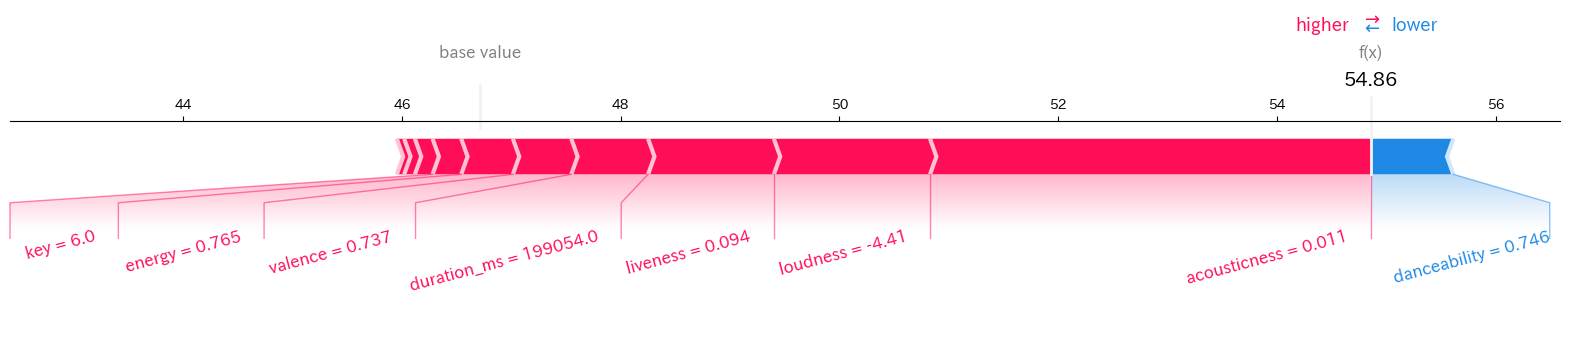

saved: step10_force_Original.png
Dynamite - Acoustic Remix / popularity=49 / predicted=47.3 / cluster C6


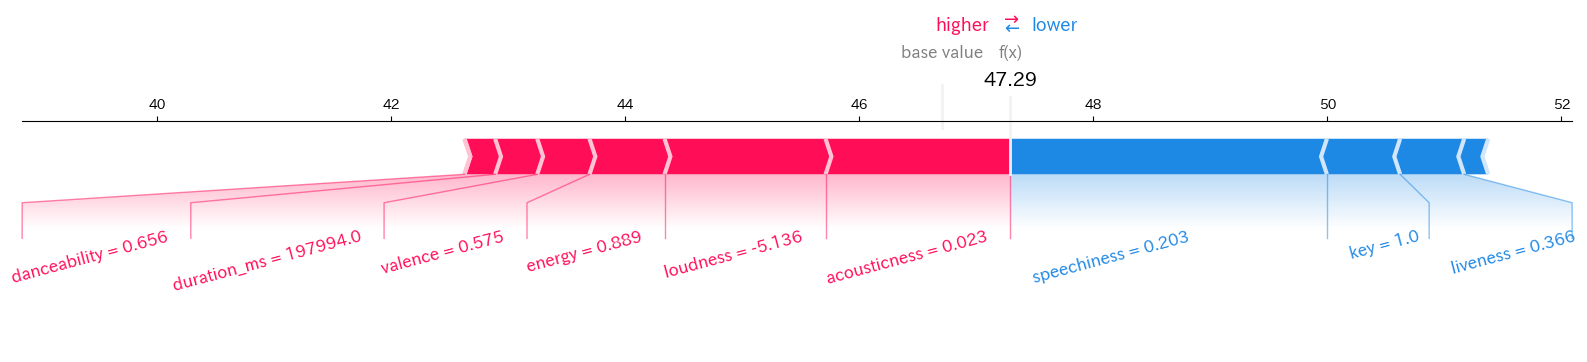

saved: step10_force_Acoustic_Remix.png
Dynamite - EDM Remix / popularity=47 / predicted=53.1 / cluster C5


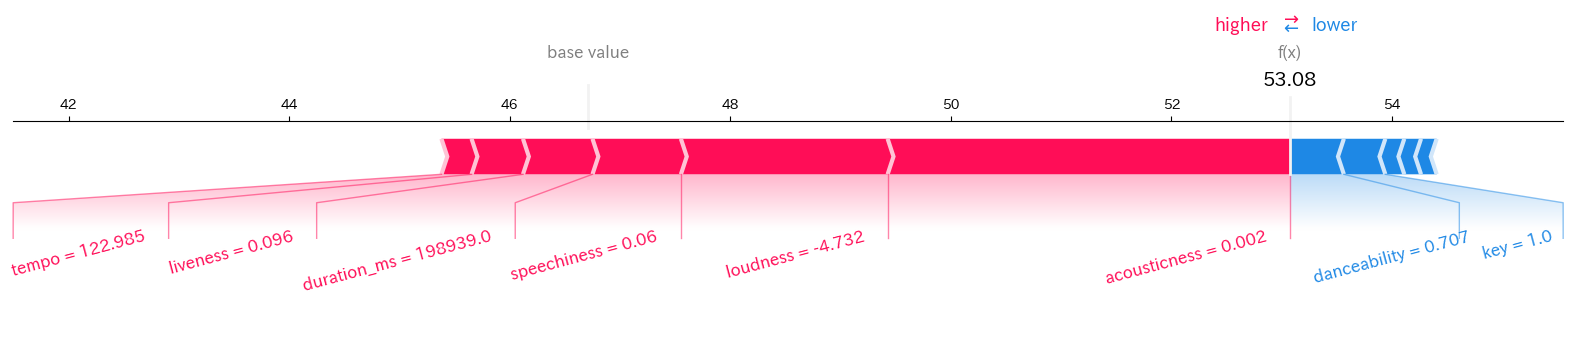

saved: step10_force_EDM_Remix.png
Dynamite - Slow Jam Remix / popularity=46 / predicted=47.8 / cluster C3


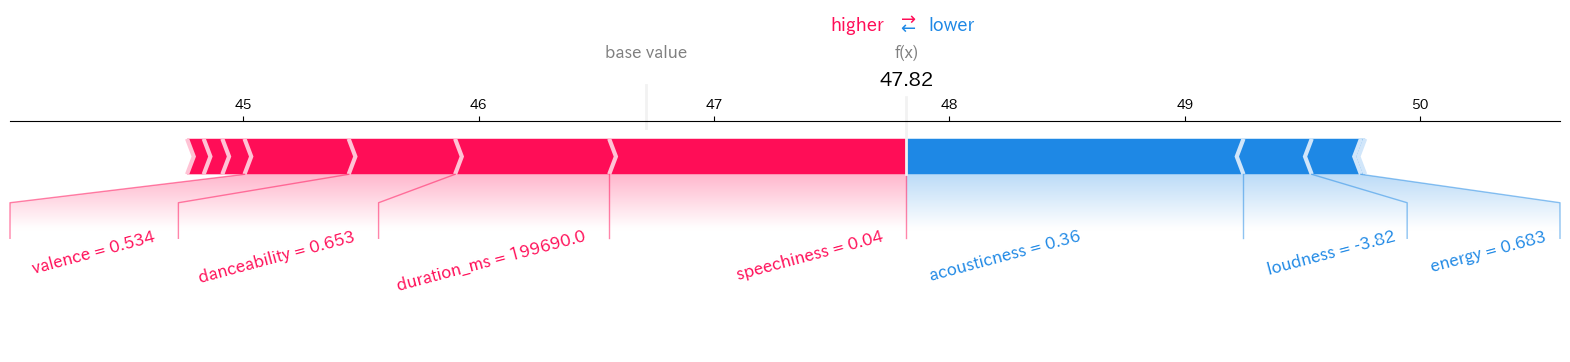

saved: step10_force_Slow_Jam_Remix.png


In [152]:
# Step10: Dynamite の force plot（赤と青の図）
# 必要な変数: df_2020（cluster_v3 付き）, shap_values_v3（cell-23 で2020年の曲に対して計算したもの）, explainer_gb2, FEATURE_COLS_V2

# shap_values_v3 は cell-23 で2020年の曲（df_2020 と同じ並び）に対して計算し直されている
assert len(shap_values_v3.values) == len(df_2020), "cell-23 を実行してからこのセルを実行してください"

TARGET_VERSIONS = ['Dynamite', 'Dynamite - Acoustic Remix', 'Dynamite - EDM Remix', 'Dynamite - Slow Jam Remix']

base_val = float(np.ravel(explainer_gb2.expected_value)[0])
pos_all = np.arange(len(df_2020))

for name in TARGET_VERSIONS:
    m = ((df_2020['track_name'] == name) & (df_2020['artist_name'] == 'BTS')).values
    if m.sum() == 0:
        print("not found:", name)
        continue
    i = int(pos_all[m][0])
    row = df_2020.iloc[i]
    pred = base_val + shap_values_v3.values[i].sum()
    print("=" * 90)
    print(f"{name} / popularity={int(row['popularity'])} / predicted={pred:.1f} / cluster C{int(row['cluster_v3'])}")
    shap.force_plot(base_val, shap_values_v3.values[i], row[FEATURE_COLS_V2].astype(float).round(3),
                    matplotlib=True, show=False, text_rotation=15)
    fname = 'step10_force_' + name.replace('Dynamite - ', '').replace('Dynamite', 'Original').replace(' ', '_') + '.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print("saved:", fname)


#Step11: クラスタごとの意味・特徴の分析

**打ち合わせメモ**: クラスタ7つの特徴分析 / 他にクラスタあるか

**出すもの**
1. **クラスタ一覧表**: 曲数、人気度（2020年と2021年）、有名アーティストの曲の割合、アーティスト数、最も曲の多いアーティスト
2. **音の特徴のヒートマップ**: クラスタごとの特徴量の平均（ジャンル2020年平均を0としたzスコア）
3. **平均SHAP値のヒートマップ**: どの特徴がそのクラスタの人気度予測を押し上げ・押し下げたか
4. **人気度の箱ひげ図**: 2020年の曲と、2021年の曲を同じクラスタに当てはめた場合を並べる
5. **クラスタごとの要約**: 平均より高い特徴・低い特徴の上位3つ

**2021年に当てはめる理由**: クラスタは2020年の曲で作っているため、クラスタ間の人気度の差が「学習データでたまたま出ただけ」の可能性がある。2021年の曲（モデルが見ていない曲）でも同じ順に差が出れば、クラスタの意味付けを信頼できる。

pop 版はクラスタ数が4（k=4）。


Step11: cluster profiles (k-pop, k=8)
genre popularity mean: 2020=46.8 / 2021=47.9
known artists found in 2020: ['(G)I-DLE', 'ATEEZ', 'BAEKHYUN', 'BLACKPINK', 'BTS', 'ENHYPEN', 'GOT7', 'ITZY', 'IU', 'IZ*ONE', 'KAI', 'MAMAMOO', 'MONSTA X', 'NCT 127', 'NCT DREAM', 'Red Velvet', 'SEVENTEEN', 'Stray Kids', 'TAEYEON', 'TOMORROW X TOGETHER', 'TREASURE', 'TWICE', 'aespa']

cluster  n_2020  pop_2020  n_2021  pop_2021  known_%  artists      top_artist
     C0      56      44.6      72      48.5     25.0       43         BTS (3)
     C1     165      49.8     171      48.8     46.1       79 Stray Kids (14)
     C2     132      45.1     132      48.1     31.8       72  Stray Kids (8)
     C3     131      47.2     149      47.1     27.5       85        BTS (11)
     C4      57      41.0      50      42.5     17.5       31    EST Gee (12)
     C5      89      52.8     109      49.1     53.9       45        BTS (13)
     C6     108      44.9     122      49.5     38.9       55     NCT 127 (6)
     C7

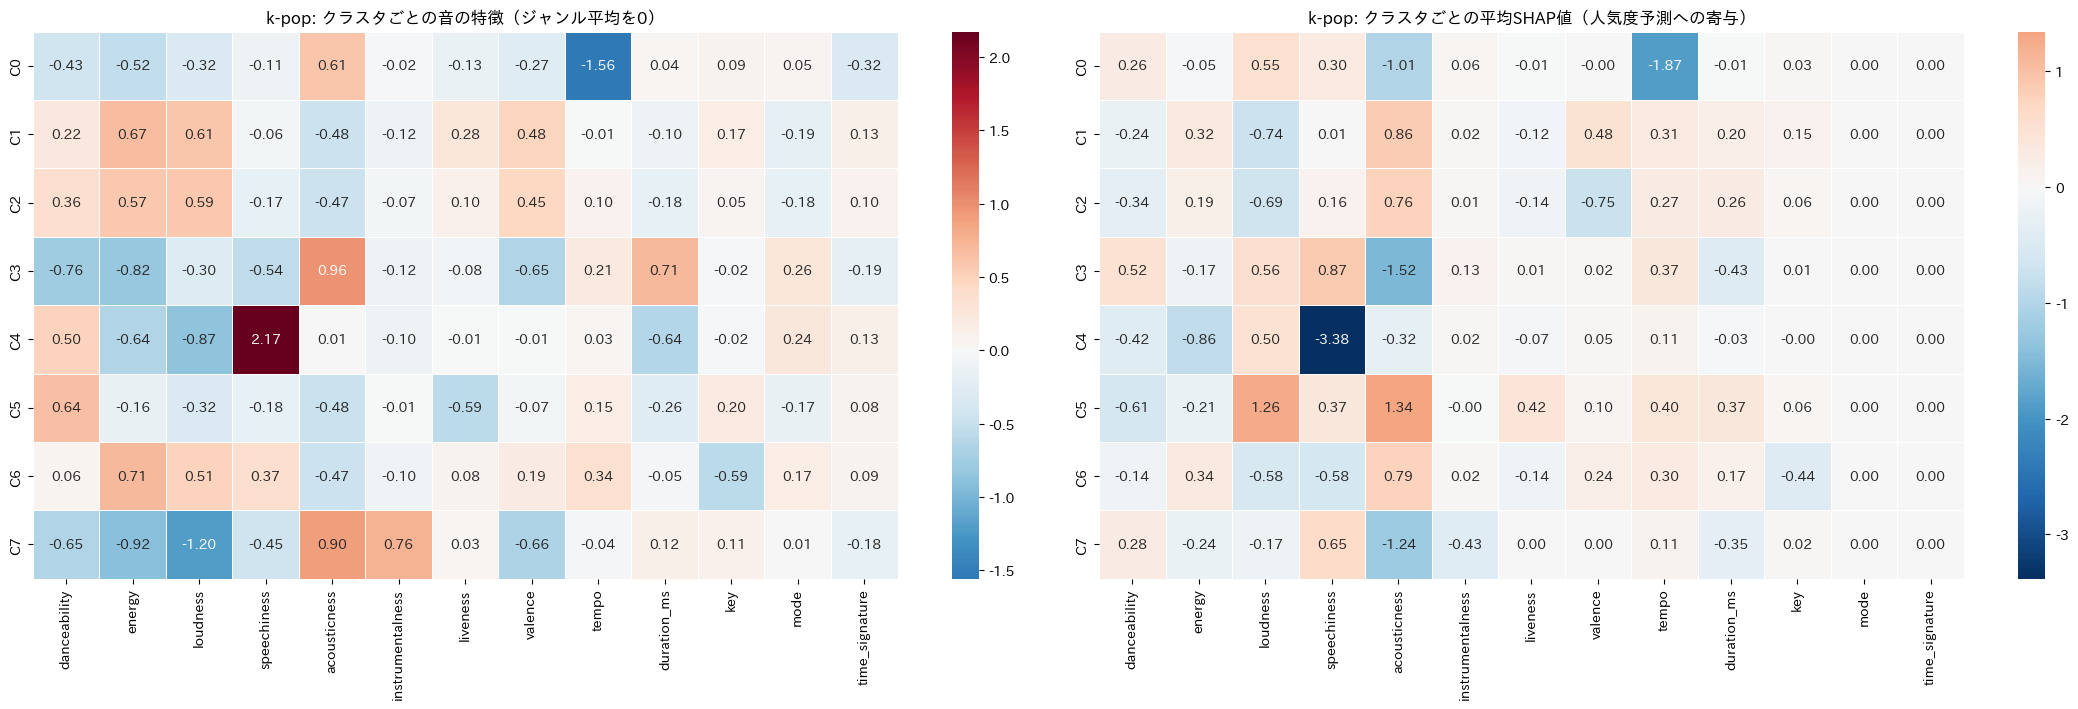

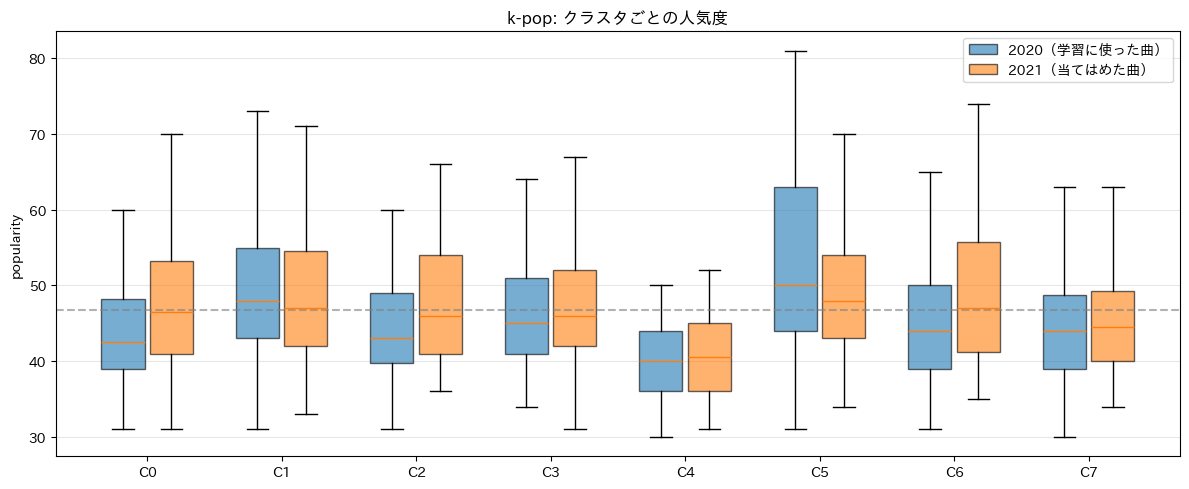

In [153]:
# Step11: クラスタごとの意味・特徴の分析
# 必要な変数: df_2020（cluster_v3 付き）, df_2021, X2_test, shap_matrix_v3（cell-23 の2020年SHAP値）,
#             explainer_gb2, scaler_v3, km_v3, FEATURE_COLS_V2, CHOSEN_K_V3, TARGET_GENRE

assert len(shap_matrix_v3) == len(df_2020), "cell-23 を実行してからこのセルを実行してください"

# 日本人がよく知っているアーティスト（ジャンル別）。データ上の表記と完全一致で照合する
KNOWN_BY_GENRE = {
    'k-pop': ['BTS', 'BLACKPINK', 'TWICE', 'Stray Kids', 'SEVENTEEN', 'TOMORROW X TOGETHER', 'ITZY',
              'IZ*ONE', 'NCT 127', 'NCT DREAM', 'ENHYPEN', '(G)I-DLE', 'MAMAMOO', 'IU', 'MONSTA X',
              'GOT7', 'ATEEZ', 'TREASURE', 'BAEKHYUN', 'TAEYEON', 'KAI', 'aespa', 'Red Velvet'],
    'pop': ['Taylor Swift', 'The Weeknd', 'Justin Bieber', 'Miley Cyrus', 'Billie Eilish', 'Ariana Grande',
            'Dua Lipa', 'Harry Styles', 'Lady Gaga', 'Ed Sheeran', 'Sam Smith', 'Joji',
            'Fujii Kaze', 'Kenshi Yonezu', 'YOASOBI', 'Ado'],
    'hip-hop': ['Drake', 'Eminem', 'Lil Nas X', 'Juice WRLD', 'Travis Scott', 'Post Malone', 'Doja Cat',
                'Megan Thee Stallion', 'Cardi B', 'Kanye West', 'Jack Harlow', '21 Savage', 'Lil Baby',
                'Future', 'Playboi Carti', 'Tyler, The Creator'],
}
known_list = KNOWN_BY_GENRE.get(TARGET_GENRE, [])
known_lower = set(a.lower() for a in known_list)

d20 = df_2020.copy()
d20['known'] = d20['artist_name'].str.lower().isin(known_lower)

# 2021年の曲を、2020年のモデル・クラスタにそのまま当てはめる
sv21 = explainer_gb2(X2_test, check_additivity=False)
d21 = df_2021.copy()
d21['cluster_v3'] = km_v3.predict(scaler_v3.transform(sv21.values))

feat_mean = d20[FEATURE_COLS_V2].mean()
feat_std = d20[FEATURE_COLS_V2].std()
z20 = (d20[FEATURE_COLS_V2] - feat_mean) / feat_std

rows = []
for k in range(CHOSEN_K_V3):
    m20 = (d20['cluster_v3'] == k).values
    m21 = (d21['cluster_v3'] == k).values
    dk = d20[m20]
    top = dk['artist_name'].value_counts()
    rows.append({
        'cluster': f'C{k}',
        'n_2020': int(m20.sum()),
        'pop_2020': round(dk['popularity'].mean(), 1),
        'n_2021': int(m21.sum()),
        'pop_2021': round(d21.loc[m21, 'popularity'].mean(), 1) if m21.sum() > 0 else np.nan,
        'known_%': round(dk['known'].mean() * 100, 1),
        'artists': int(dk['artist_name'].nunique()),
        'top_artist': f"{top.index[0]} ({top.iloc[0]})",
    })
profile = pd.DataFrame(rows)

print(f"Step11: cluster profiles ({TARGET_GENRE}, k={CHOSEN_K_V3})")
print("=" * 100)
print(f"genre popularity mean: 2020={d20['popularity'].mean():.1f} / 2021={d21['popularity'].mean():.1f}")
print(f"known artists found in {TARGET_YEAR}: {sorted(set(d20.loc[d20['known'], 'artist_name']))}")
print()
print(profile.to_string(index=False))

# 音の特徴（ジャンル2020年平均を0としたzスコアの平均）
zprof = z20.groupby(d20['cluster_v3'].values).mean()
zprof.index = [f'C{k}' for k in zprof.index]
print()
print("feature profile (mean z-score, 0 = genre 2020 average)")
print(zprof.round(2).to_string())

# SHAPの傾向（クラスタごとの平均SHAP値）
sprof = pd.DataFrame(shap_matrix_v3, columns=FEATURE_COLS_V2).groupby(d20['cluster_v3'].values).mean()
sprof.index = [f'C{k}' for k in sprof.index]
print()
print("SHAP profile (mean SHAP value)")
print(sprof.round(2).to_string())

# クラスタごとの要約
print()
print("=== cluster summary ===")
for k in range(CHOSEN_K_V3):
    zk = zprof.iloc[k].sort_values()
    high = ", ".join(f"{f}({v:+.2f})" for f, v in zk.tail(3)[::-1].items())
    low = ", ".join(f"{f}({v:+.2f})" for f, v in zk.head(3).items())
    p = profile.iloc[k]
    print(f"C{k}: n={p['n_2020']}  pop2020={p['pop_2020']}  pop2021={p['pop_2021']}  known={p['known_%']}%  top={p['top_artist']}")
    print("    high: " + high)
    print("    low : " + low)

# 図1: 音の特徴とSHAPのヒートマップ
fig, axes = plt.subplots(1, 2, figsize=(22, max(4, CHOSEN_K_V3 * 0.9)))
sns.heatmap(zprof, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5, ax=axes[0])
axes[0].set_title(f"{TARGET_GENRE}: クラスタごとの音の特徴（ジャンル平均を0）", fontsize=12, fontweight='bold')
sns.heatmap(sprof, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5, ax=axes[1])
axes[1].set_title(f"{TARGET_GENRE}: クラスタごとの平均SHAP値（人気度予測への寄与）", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'step11_profiles_{TARGET_GENRE}.png', dpi=150, bbox_inches='tight')
plt.show()

# 図2: クラスタごとの人気度（青=2020年、橙=2021年を当てはめ）
fig, ax = plt.subplots(figsize=(12, 5))
pos = np.arange(CHOSEN_K_V3)
data20 = [d20.loc[d20['cluster_v3'] == k, 'popularity'].values for k in range(CHOSEN_K_V3)]
data21 = [d21.loc[d21['cluster_v3'] == k, 'popularity'].values for k in range(CHOSEN_K_V3)]
data21 = [x if len(x) > 0 else np.array([np.nan]) for x in data21]
b1 = ax.boxplot(data20, positions=pos - 0.18, widths=0.32, patch_artist=True, showfliers=False)
b2 = ax.boxplot(data21, positions=pos + 0.18, widths=0.32, patch_artist=True, showfliers=False)
for patch in b1['boxes']:
    patch.set_facecolor('tab:blue')
    patch.set_alpha(0.6)
for patch in b2['boxes']:
    patch.set_facecolor('tab:orange')
    patch.set_alpha(0.6)
ax.set_xticks(pos)
ax.set_xticklabels([f'C{k}' for k in range(CHOSEN_K_V3)])
ax.axhline(d20['popularity'].mean(), color='gray', linestyle='--', alpha=0.6)
ax.legend([b1['boxes'][0], b2['boxes'][0]], ['2020（学習に使った曲）', '2021（当てはめた曲）'])
ax.set_ylabel('popularity')
ax.set_title(f"{TARGET_GENRE}: クラスタごとの人気度", fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'step11_popularity_{TARGET_GENRE}.png', dpi=150, bbox_inches='tight')
plt.show()


#Step12: 「C4 のようなクラスタ」は他にあるか

**打ち合わせメモ**: C4が他にあるか / popでも調べて

k=7 のときの C4 は、人気度が最も高く（53.6）、有名アーティストの曲が集中していた「ヒット曲クラスタ」だった（k=8 ではクラスタの番号と中身が変わる）。
同じように人気度が高いクラスタが他にもあるかを、統計的に確かめる。

- 各クラスタについて「そのクラスタの平均人気度 − それ以外の平均人気度」と、その95%信頼区間（ブートストラップ2000回）を出す
- **2020年（学習に使った曲）と2021年（当てはめた曲）の両方で差がプラス** → 本当に人気度が高いクラスタと判定
- 2020年だけプラス → 学習データでたまたま出た可能性がある

**ジャンルをまたいだ比較**（pop にも k-pop の C4 と似た音のクラスタがあるか）は、両ジャンルを実行して GitHub に保存した後、Step11 の「音の特徴」を並べて比べる。


In [154]:
# Step12: 人気度が高い（または低い）クラスタの判定
# 必要な変数: d20, d21（Step11 で作成）, CHOSEN_K_V3, TARGET_GENRE

N_BOOT_H = 2000
rng_h = np.random.default_rng(0)


def diff_ci(x, rest):
    # クラスタの平均 − それ以外の平均 と、その95%信頼区間
    if len(x) < 5 or len(rest) < 5:
        return np.nan, np.nan, np.nan
    d = x.mean() - rest.mean()
    bs = np.empty(N_BOOT_H)
    for b in range(N_BOOT_H):
        bs[b] = rng_h.choice(x, len(x)).mean() - rng_h.choice(rest, len(rest)).mean()
    return d, np.percentile(bs, 2.5), np.percentile(bs, 97.5)


rows = []
for k in range(CHOSEN_K_V3):
    p20 = d20.loc[d20['cluster_v3'] == k, 'popularity'].values
    r20 = d20.loc[d20['cluster_v3'] != k, 'popularity'].values
    p21 = d21.loc[d21['cluster_v3'] == k, 'popularity'].values
    r21 = d21.loc[d21['cluster_v3'] != k, 'popularity'].values
    a, al, ah = diff_ci(p20, r20)
    b, bl, bh = diff_ci(p21, r21)
    if al > 0 and bl > 0:
        verdict = 'HIGH (both years)'
    elif ah < 0 and bh < 0:
        verdict = 'LOW (both years)'
    elif al > 0:
        verdict = 'high in 2020 only'
    elif ah < 0:
        verdict = 'low in 2020 only'
    else:
        verdict = '-'
    rows.append({
        'cluster': f'C{k}',
        'diff_2020': round(a, 2), 'ci_2020': f"[{al:+.2f}, {ah:+.2f}]",
        'diff_2021': round(b, 2), 'ci_2021': f"[{bl:+.2f}, {bh:+.2f}]",
        'verdict': verdict,
    })

hit_table = pd.DataFrame(rows)
print(f"Step12: popularity difference vs other clusters ({TARGET_GENRE})")
print("=" * 90)
print(hit_table.to_string(index=False))
print()
print("diff = cluster mean - mean of all other tracks (popularity points)")
print("HIGH (both years) = 95% CI above 0 in 2020 AND in 2021")


Step12: popularity difference vs other clusters (k-pop)
cluster  diff_2020        ci_2020  diff_2021        ci_2021           verdict
     C0      -2.40 [-4.74, +0.23]       0.66 [-1.58, +2.87]                 -
     C1       3.80 [+2.26, +5.49]       1.11 [-0.53, +2.61] high in 2020 only
     C2      -2.06 [-3.61, -0.51]       0.29 [-1.17, +1.81]  low in 2020 only
     C3       0.47 [-1.20, +2.14]      -0.94 [-2.25, +0.39]                 -
     C4      -6.23 [-8.19, -4.18]      -5.70 [-8.28, -3.15]  LOW (both years)
     C5       6.74 [+4.30, +9.25]       1.35 [-0.34, +3.04] high in 2020 only
     C6      -2.23 [-3.77, -0.67]       1.93 [+0.02, +3.93]  low in 2020 only
     C7      -2.64 [-4.35, -0.78]      -2.77 [-4.54, -1.01]  LOW (both years)

diff = cluster mean - mean of all other tracks (popularity points)
HIGH (both years) = 95% CI above 0 in 2020 AND in 2021


#Step13: 知っているアーティストの曲がどのクラスタに入るか（2020年）

**打ち合わせメモ**: 知っているアーティストが（Dynamite の時のように）どのクラスタに属する曲を持っているか（K-pop, pop）/ 同じ人で別のクラスタに入っているのを確認

**出すもの**
1. **アーティスト × クラスタの曲数表**（全曲／リミックスや別バージョンを除いた場合）とヒートマップ
2. **アーティストごとのまとめ**: 曲数、入っているクラスタの数、最も多いクラスタとその割合
3. **同じアーティストで別のクラスタに入った曲**: クラスタごとに代表曲を並べる（聴き比べ候補、Spotify リンク付き）
4. **同じ曲の別バージョン**がどのクラスタに入ったか（Dynamite の分析を全曲に広げたもの）

**別バージョンを分ける理由**: BTS の2020年42曲のうち10曲は Dynamite のリミックス。そのまま数えるとアーティストの分布がゆがむ。

**注意**: pop の日本人アーティスト（藤井風・米津玄師・YOASOBI・Ado）は2020年に1曲ずつしかないため、ここでは「別のクラスタに入るか」を確認できない。年代を広げる次の作業で確認する。

全結果は CSV（`artist_cluster_<ジャンル>_2020.csv`）にも保存する。


Step13: known artists in k-pop 2020
found  : ['BTS', 'BLACKPINK', 'TWICE', 'Stray Kids', 'SEVENTEEN', 'TOMORROW X TOGETHER', 'ITZY', 'IZ*ONE', 'NCT 127', 'NCT DREAM', 'ENHYPEN', '(G)I-DLE', 'MAMAMOO', 'IU', 'MONSTA X', 'GOT7', 'ATEEZ', 'TREASURE', 'BAEKHYUN', 'TAEYEON', 'KAI', 'aespa', 'Red Velvet']
missing: []

--- tracks per cluster (all tracks) ---
                     C0  C1  C2  C3  C4  C5  C6  C7
artist_name                                        
BTS                   3   3   3  11   2  13   5   2
Stray Kids            0  14   8   1   1   6   3   1
TWICE                 1  12   1   0   1   4   6   2
MONSTA X              0   5   3   3   2   4   2   0
IZ*ONE                1   7   4   2   0   0   5   0
NCT 127               1   3   1   4   0   0   6   1
TOMORROW X TOGETHER   0   3   5   1   0   2   3   1
SEVENTEEN             1   3   3   2   0   2   3   0
BAEKHYUN              1   3   0   5   0   0   1   3
ATEEZ                 0   6   2   1   0   1   1   1
ITZY                  

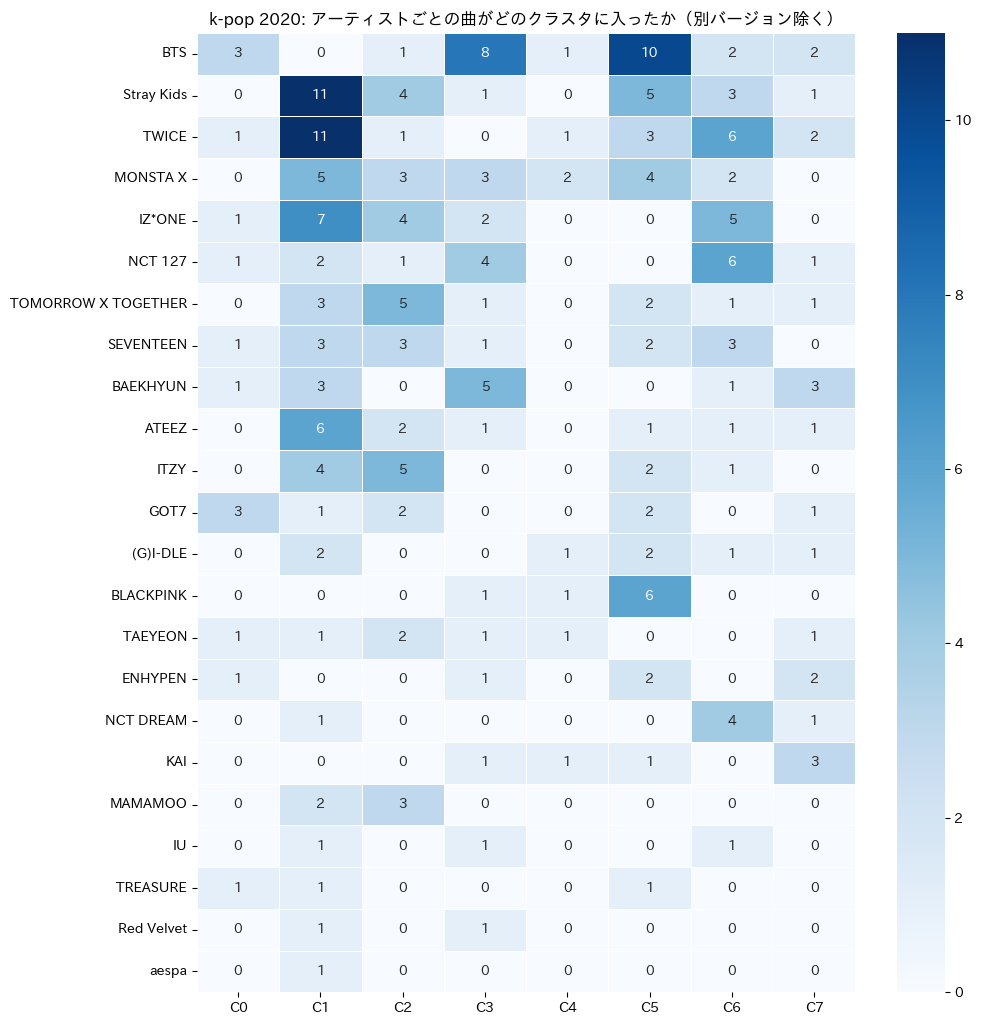


=== same artist, different clusters (listening candidates) ===
----------------------------------------------------------------------------------------------------
BTS: 27 tracks in 7 clusters
    C0  We are Bulletproof : the Eternal          pop= 68  https://open.spotify.com/track/133ocfbXXG4HTk76qgSeUb
    C0  Friends                                   pop= 68  https://open.spotify.com/track/5RjUtRlDonw3TBgGGMLC5b
    C0  Life Goes On                              pop= 76  https://open.spotify.com/track/5FVbvttjEvQ8r2BgUcJgNg
    C2  Boy With Luv (Feat. Halsey)               pop= 68  https://open.spotify.com/track/7lrqvdivAYRGEiO8JFP31G
    C3  Blue & Grey                               pop= 69  https://open.spotify.com/track/7Ki0hse0IfXEcXUlpyECbJ
    C3  Your eyes tell                            pop= 64  https://open.spotify.com/track/3TZ7NHkMT82AhwuYsd00Hz
    C3  ON                                        pop= 71  https://open.spotify.com/track/0fZRNhPJ4AGmwY7rkpdbqK
    C4  Fly To 

In [155]:
# Step13: 知っているアーティストの曲がどのクラスタに入るか（2020年）
# 必要な変数: d20, known_list（Step11 で作成）, km_v3, shap_scaled_v3, CHOSEN_K_V3, TARGET_GENRE, TARGET_YEAR

# リミックスや別バージョンを見分けるための語（曲名を小文字にして部分一致）
VERSION_WORDS = ['remix', 'ver.', 'version', 'instrumental', 'inst.', 'acoustic', '(live', '- live',
                 'sped up', 'slowed', 'remaster', ' edit', 'mix)']

titles = d20['track_name'].fillna('').astype(str)
d20['is_version'] = titles.str.lower().apply(lambda t: any(w in t for w in VERSION_WORDS))
# 曲名の「 - 」や「 (」より前を元の曲名とみなす（例: "Dynamite - EDM Remix" -> "dynamite"）
d20['base_title'] = titles.str.split(' - ').str[0].str.split(' (', regex=False).str[0].str.strip().str.lower()
d20['spotify_url'] = 'https://open.spotify.com/track/' + d20['track_id'].astype(str)
d20['dist'] = np.linalg.norm(shap_scaled_v3 - km_v3.cluster_centers_[d20['cluster_v3'].values], axis=1)

found = [a for a in known_list if (d20['artist_name'].str.lower() == a.lower()).any()]
missing = [a for a in known_list if a not in found]
print(f"Step13: known artists in {TARGET_GENRE} {TARGET_YEAR}")
print("=" * 100)
print("found  :", found)
print("missing:", missing)

sub = d20[d20['artist_name'].str.lower().isin([a.lower() for a in found])].copy()
cols = list(range(CHOSEN_K_V3))
ct_all = pd.crosstab(sub['artist_name'], sub['cluster_v3']).reindex(columns=cols, fill_value=0)
orig = sub[~sub['is_version']]
ct_orig = pd.crosstab(orig['artist_name'], orig['cluster_v3']).reindex(index=ct_all.index, columns=cols, fill_value=0)
order = ct_all.sum(axis=1).sort_values(ascending=False).index
ct_all = ct_all.loc[order]
ct_orig = ct_orig.loc[order]
ct_all.columns = [f'C{k}' for k in cols]
ct_orig.columns = [f'C{k}' for k in cols]

print()
print("--- tracks per cluster (all tracks) ---")
print(ct_all.to_string())
print()
print("--- tracks per cluster (remixes / other versions removed) ---")
print(ct_orig.to_string())

# アーティストごとのまとめ（別バージョンを除いた曲で数える）
summ = pd.DataFrame({
    'tracks_all': ct_all.sum(axis=1),
    'tracks_orig': ct_orig.sum(axis=1),
    'clusters_used': (ct_orig > 0).sum(axis=1),
    'main_cluster': ct_orig.idxmax(axis=1),
    'main_share_%': (ct_orig.max(axis=1) / ct_orig.sum(axis=1).replace(0, np.nan) * 100).round(1),
})
print()
print("--- artist summary (remixes / other versions removed) ---")
print(summ.to_string())

# 図: アーティスト × クラスタ（別バージョンを除いた曲数）
fig, ax = plt.subplots(figsize=(max(8, CHOSEN_K_V3 * 1.3), max(4, len(ct_orig) * 0.45)))
sns.heatmap(ct_orig, annot=True, fmt='d', cmap='Blues', linewidths=0.5, ax=ax)
ax.set_title(f"{TARGET_GENRE} {TARGET_YEAR}: アーティストごとの曲がどのクラスタに入ったか（別バージョン除く）", fontsize=12, fontweight='bold')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(f'step13_artist_cluster_{TARGET_GENRE}.png', dpi=150, bbox_inches='tight')
plt.show()

# 同じアーティストで別のクラスタに入った曲（クラスタの中心に近い順に最大3曲）
print()
print("=== same artist, different clusters (listening candidates) ===")
for artist in order:
    a_orig = orig[orig['artist_name'] == artist]
    if a_orig['cluster_v3'].nunique() < 2:
        continue
    print("-" * 100)
    print(f"{artist}: {len(a_orig)} tracks in {a_orig['cluster_v3'].nunique()} clusters")
    for k, grp in a_orig.groupby('cluster_v3'):
        for _, r in grp.nsmallest(3, 'dist').iterrows():
            print(f"    C{int(k)}  {str(r['track_name'])[:40]:<42}pop={int(r['popularity']):>3}  {r['spotify_url']}")

# 同じ曲の別バージョン（Dynamite の分析を全曲に広げたもの）
print()
print("=== same song, multiple versions ===")
multi = sub.groupby(['artist_name', 'base_title']).filter(lambda g: len(g) >= 2)
if len(multi) == 0:
    print("(none)")
for (artist, title), grp in multi.groupby(['artist_name', 'base_title']):
    cl_used = sorted(grp['cluster_v3'].unique().tolist())
    print("-" * 100)
    print(f"{artist} / {title}: {len(grp)} versions -> clusters {['C' + str(c) for c in cl_used]}")
    for _, r in grp.sort_values('popularity', ascending=False).iterrows():
        print(f"    C{int(r['cluster_v3'])}  {str(r['track_name'])[:46]:<48}pop={int(r['popularity']):>3}")

# CSV保存
out_cols = ['artist_name', 'track_name', 'popularity', 'cluster_v3', 'is_version', 'base_title', 'dist', 'spotify_url']
csv_name = f"artist_cluster_{TARGET_GENRE}_{TARGET_YEAR}.csv"
sub.sort_values(['artist_name', 'cluster_v3', 'dist'])[out_cols].to_csv(csv_name, index=False, encoding='utf-8-sig')
print()
print("saved:", csv_name)


#Step14: 曲の2次元マップ（k=8）

**打ち合わせメモ**: 8次元を2次元に / 2次元のマップ表示してグループを特徴づける

- 各曲の SHAP 値（13次元、標準化済み）を**主成分分析（PCA）で2次元**に縮めて散布図にする。色は k=8 のクラスタ
- 知っている曲には名前を付ける
- 軸の意味は「主成分負荷」の表で確認する（どの特徴の SHAP 値が、軸の向きを決めているか）

**注意**: 2次元に縮めると情報の一部が落ちる。表示される「説明率」が低いと、図の上で重なって見えるクラスタも、元の13次元では離れていることがある。

PCA explained variance: PC1=15.8%  PC2=11.3%  (total 27.2%)

loadings (which feature's SHAP value drives each axis)
                   PC1   PC2
loudness         -0.37 -0.42
danceability     -0.30  0.54
speechiness      -0.18  0.53
liveness         -0.14 -0.13
key              -0.12 -0.01
mode              0.00  0.00
time_signature    0.00  0.00
instrumentalness  0.10 -0.10
valence           0.11 -0.02
tempo             0.26  0.01
duration_ms       0.38 -0.12
energy            0.45  0.44
acousticness      0.52 -0.11


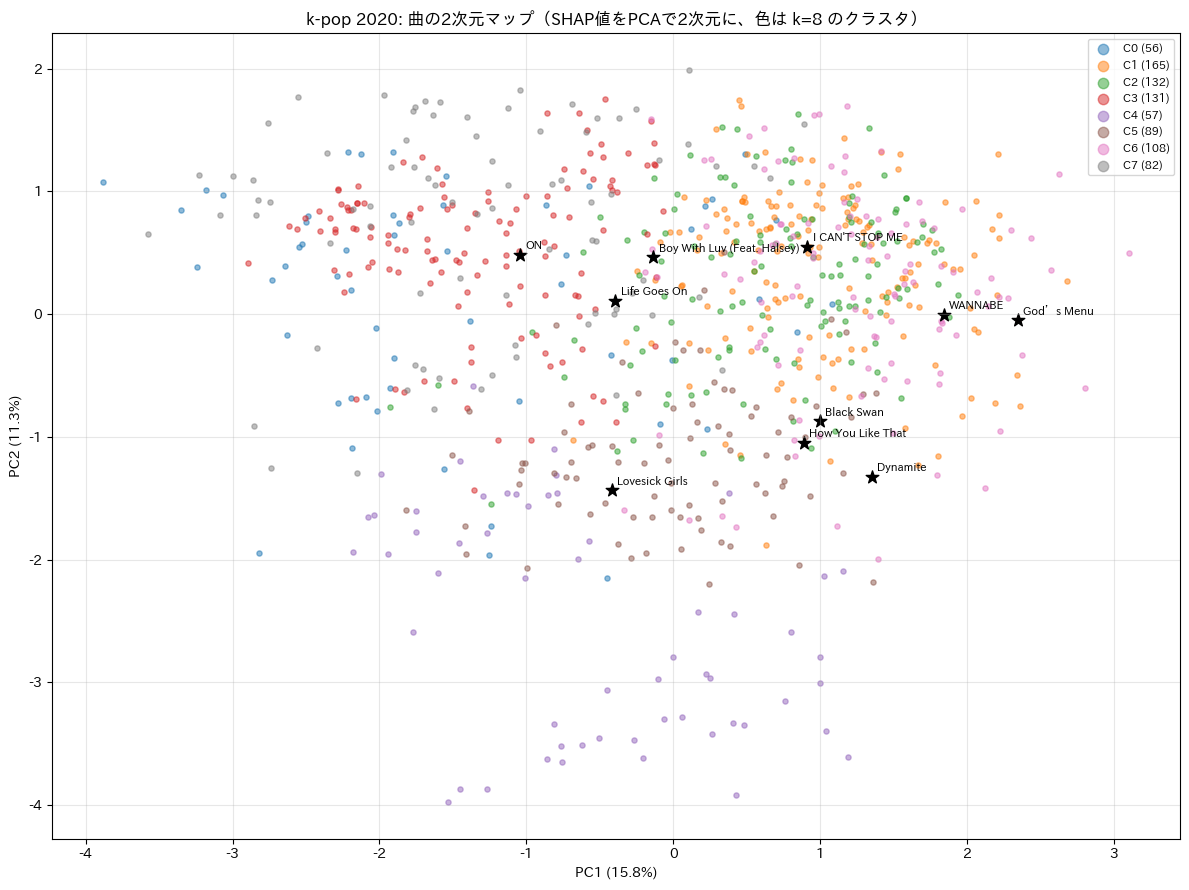

In [156]:
# Step14: 曲の2次元マップ（SHAP値をPCAで2次元に）
# 必要な変数: shap_scaled_v3（cell-24）, df_2020（cluster_v3 付き）, FEATURE_COLS_V2, CHOSEN_K_V3, TARGET_GENRE, TARGET_YEAR

from sklearn.decomposition import PCA

pca_song = PCA(n_components=2, random_state=42)
xy_song = pca_song.fit_transform(shap_scaled_v3)
ev = pca_song.explained_variance_ratio_
print(f"PCA explained variance: PC1={ev[0]*100:.1f}%  PC2={ev[1]*100:.1f}%  (total {ev.sum()*100:.1f}%)")

# 軸の意味（主成分負荷）
load_song = pd.DataFrame(pca_song.components_.T, index=FEATURE_COLS_V2, columns=['PC1', 'PC2'])
print()
print("loadings (which feature's SHAP value drives each axis)")
print(load_song.round(2).sort_values('PC1').to_string())

LABEL_TRACKS = ['Dynamite', 'How You Like That', 'Life Goes On', "I CAN'T STOP ME", 'WANNABE',
                'ON', 'Black Swan', 'Boy With Luv (Feat. Halsey)', 'Lovesick Girls', 'God’s Menu']

fig, ax = plt.subplots(figsize=(12, 9))
for k in range(CHOSEN_K_V3):
    m = (df_2020['cluster_v3'] == k).values
    ax.scatter(xy_song[m, 0], xy_song[m, 1], s=14, alpha=0.5, color=plt.cm.tab10(k % 10), label=f'C{k} ({m.sum()})')
for t in LABEL_TRACKS:
    idx = np.where((df_2020['track_name'] == t).values)[0]
    if len(idx) == 0:
        continue
    i = int(idx[0])
    ax.scatter(xy_song[i, 0], xy_song[i, 1], s=90, color='black', marker='*')
    ax.annotate(t, (xy_song[i, 0], xy_song[i, 1]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel(f'PC1 ({ev[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({ev[1]*100:.1f}%)')
ax.set_title(f"{TARGET_GENRE} {TARGET_YEAR}: 曲の2次元マップ（SHAP値をPCAで2次元に、色は k={CHOSEN_K_V3} のクラスタ）", fontsize=12, fontweight='bold')
ax.legend(fontsize=8, markerscale=2, loc='best')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('step14_song_map.png', dpi=150, bbox_inches='tight')
plt.show()

#Step15: 年代を広げる（K-POP 2018〜2022年・J-POP 全年）

**打ち合わせメモ**: 年代を広げる / K-POP 少し年代増やす / J-POP もっと年代増やして / 件数が多ければ日本人も

**方法**: 2020年 k-pop のモデルと k=8 のクラスタはそのままにして、他の年の曲を「一番近いクラスタ」に当てはめる。クラスタの定義が全年で共通になるので、年やアーティストをまたいで比べられる。

- **K-POP**: k-pop ジャンルの2018〜2022年（各年800曲以上）
- **J-POP**: 日本人アーティストの全年の曲。データには J-POP というジャンルがなく、日本人の曲は emo・acoustic・metal などに散らばっているため、**アーティスト名で集める**。曲数の多い人に加えて、若い世代に人気の4組（YOASOBI・米津玄師・Ado・藤井風。各2〜5曲）も入れる
- Perfume・CAPSULE・KIRINJI はデータ上 k-pop に分類されているが、J-POP として扱う
- 「Eve」は同名の別アーティストが混ざっているため対象外

**注意**: 2020年以外の曲と、k-pop 以外のジャンルの曲は、モデルにとって見慣れない曲になる（参考値）。人気度は年によって水準が違うので、**年をまたいで人気度は比べず、どのクラスタに入ったかだけを比べる**。

In [157]:
# Step15: 年代を広げる（K-POP 2018〜2022年、J-POP 全年）
# 必要な変数: df_clean, explainer_gb2, scaler_v3, km_v3（k=8 で作ったもの）, FEATURE_COLS_V2, CHOSEN_K_V3

KPOP_YEARS = list(range(2018, 2023))
JPOP_ARTISTS = [
    'ASIAN KUNG-FU GENERATION', 'Hikaru Utada', 'ONE OK ROCK', 'CAPSULE', 'Masayoshi Yamazaki',
    'RADWIMPS', 'Perfume', 'Shikao Suga', 'Tamio Okuda', 'KIRINJI', 'Kazuyoshi Saito', 'Aimyon',
    'BABYMETAL', 'Naotaro Moriyama', 'Yosui Inoue', 'Yuuri', 'Vaundy',
    'YOASOBI', 'Kenshi Yonezu', 'Ado', 'Fujii Kaze',
]
jpop_lower = set(a.lower() for a in JPOP_ARTISTS)

jp = df_clean[df_clean['artist_name'].str.lower().isin(jpop_lower)].copy()
jp['group'] = 'J-POP'
kp = df_clean[(df_clean['genre'] == 'k-pop') & (df_clean['year'].isin(KPOP_YEARS))].copy()
kp['group'] = 'K-POP'

# 同じ曲が複数のジャンルに入っている場合は1曲にまとめる（J-POP を優先）
multi = pd.concat([jp, kp], ignore_index=True).drop_duplicates(subset='track_id', keep='first').reset_index(drop=True)
# k-pop ジャンルに分類されている日本人アーティスト（Perfume など）は J-POP として扱う
multi.loc[multi['artist_name'].str.lower().isin(jpop_lower), 'group'] = 'J-POP'

print(f"computing SHAP values for {len(multi):,} tracks ...")
sv_multi = explainer_gb2(multi[FEATURE_COLS_V2], check_additivity=False)
shap_multi = sv_multi.values
multi['cluster_v3'] = km_v3.predict(scaler_v3.transform(shap_multi))

print()
print("Step15: tracks by group and year")
print("=" * 90)
print(pd.crosstab(multi['group'], multi['year']).to_string())

print()
print("J-POP artists: tracks / years / genres in the data")
for a in JPOP_ARTISTS:
    d = multi[multi['artist_name'].str.lower() == a.lower()]
    if len(d) == 0:
        print(f"  {a}: not found")
        continue
    gs = ", ".join(f"{g}:{n}" for g, n in d['genre'].value_counts().items())
    print(f"  {a:<26}{len(d):>4}  {int(d['year'].min())}-{int(d['year'].max())}  {gs}")

cl_cols = [f'C{k}' for k in range(CHOSEN_K_V3)]

# グループごとのクラスタの割合（%）
share = pd.crosstab(multi['group'], multi['cluster_v3'], normalize='index').reindex(columns=range(CHOSEN_K_V3), fill_value=0) * 100
share.columns = cl_cols
print()
print("cluster share by group (%)")
print(share.round(1).to_string())

# K-POP: 年ごとのクラスタの割合（%）
ky = multi[multi['group'] == 'K-POP']
share_y = pd.crosstab(ky['year'], ky['cluster_v3'], normalize='index').reindex(columns=range(CHOSEN_K_V3), fill_value=0) * 100
share_y.columns = cl_cols
print()
print("K-POP: cluster share by year (%)")
print(share_y.round(1).to_string())

computing SHAP values for 5,627 tracks ...

Step15: tracks by group and year
year   2000  2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023
group                                                                                                                                                
J-POP    91    88   147    84    65    54   103    70    84    26    51    24    55    46     6    52    31    34    38    64    27    26    94    26
K-POP     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0   848   878   820   873   822     0

J-POP artists: tracks / years / genres in the data
  ASIAN KUNG-FU GENERATION   156  2003-2023  emo:122, punk-rock:34
  Hikaru Utada               136  2000-2023  singer-songwriter:111, songwriter:17, pop:8
  ONE OK ROCK                130  2007-2022  emo:128, k-pop:2
  CAPSULE                    126  2001-2015  k-pop:82

#Step16: アーティストごとのクラスタの割合と、アーティストの地図

**打ち合わせメモ**: アーティストごとの件数でなく割合で（グラフ）/ 8次元を2次元に / グループを特徴づける / アーティストが曲を作る時にどういうものを作っているか

- 各アーティストを「**8つのクラスタそれぞれに入った曲の割合**」（8つの数値＝8次元）で表す。これがそのアーティストの「作る曲のタイプの構成」
- **100%積み上げ棒グラフ**: アーティストごとの構成
- **アーティストの地図**: 8つの割合を PCA で2次元に縮めて、アーティストを点で描く。**近いアーティストほど、似た構成の曲を作っている**。矢印は「そのクラスタの曲が多いほど、この向きに位置する」ことを表す
- **グループ分け**: 割合が似ているアーティスト同士を KMeans で `ART_GROUPS` 個のグループに分け、グループごとの平均の構成で特徴づける
- 対象: 曲が10曲以上あるアーティスト（K-POP は Step11 の有名アーティスト、J-POP は Step15 のリスト）。曲数が少ないと割合がぶれるため

artists with >= 10 tracks: 40
excluded (too few tracks): Ado(3), Fujii Kaze(2), Kenshi Yonezu(3), YOASOBI(5)
PCA explained variance: PC1=49.5%  PC2=25.4%  (total 74.9%)

cluster share per artist (%)
                            K/J art_group  tracks    C0    C1    C2    C3   C4    C5    C6    C7
artist_name                                                                                     
ONE OK ROCK               J-POP        G0     130   7.7  18.5  25.4  10.0  0.8  13.8  12.3  11.5
RADWIMPS                  J-POP        G0     110   5.5  17.3  12.7  19.1  0.0   4.5  20.9  20.0
Vaundy                    J-POP        G0      21   0.0  14.3  14.3  14.3  4.8  23.8   9.5  19.0
(G)I-DLE                  K-POP        G0      53   7.5  28.3  22.6   3.8  1.9  13.2   9.4  13.2
ATEEZ                     K-POP        G0      96   4.2  25.0  15.6  15.6  1.0  14.6  14.6   9.4
BLACKPINK                 K-POP        G0      55   1.8  14.5  16.4  12.7  9.1  27.3  18.2   0.0
BTS                      

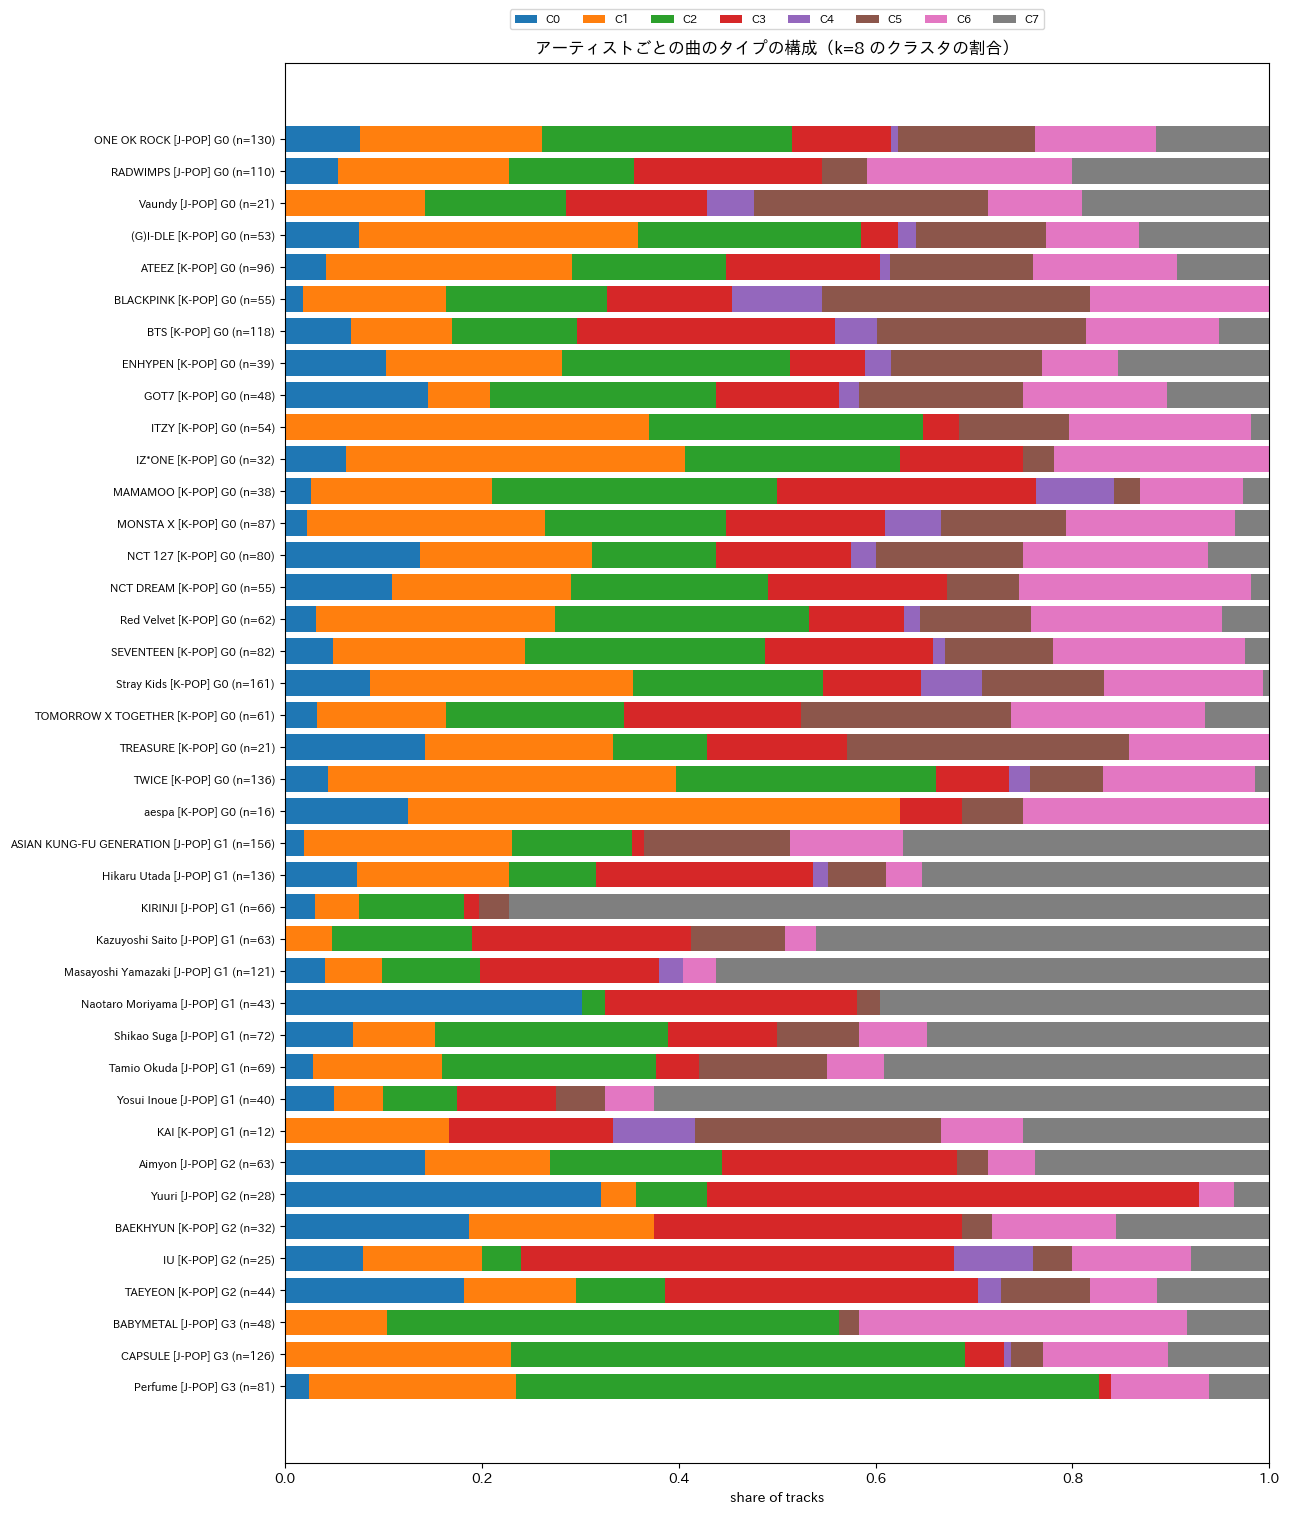

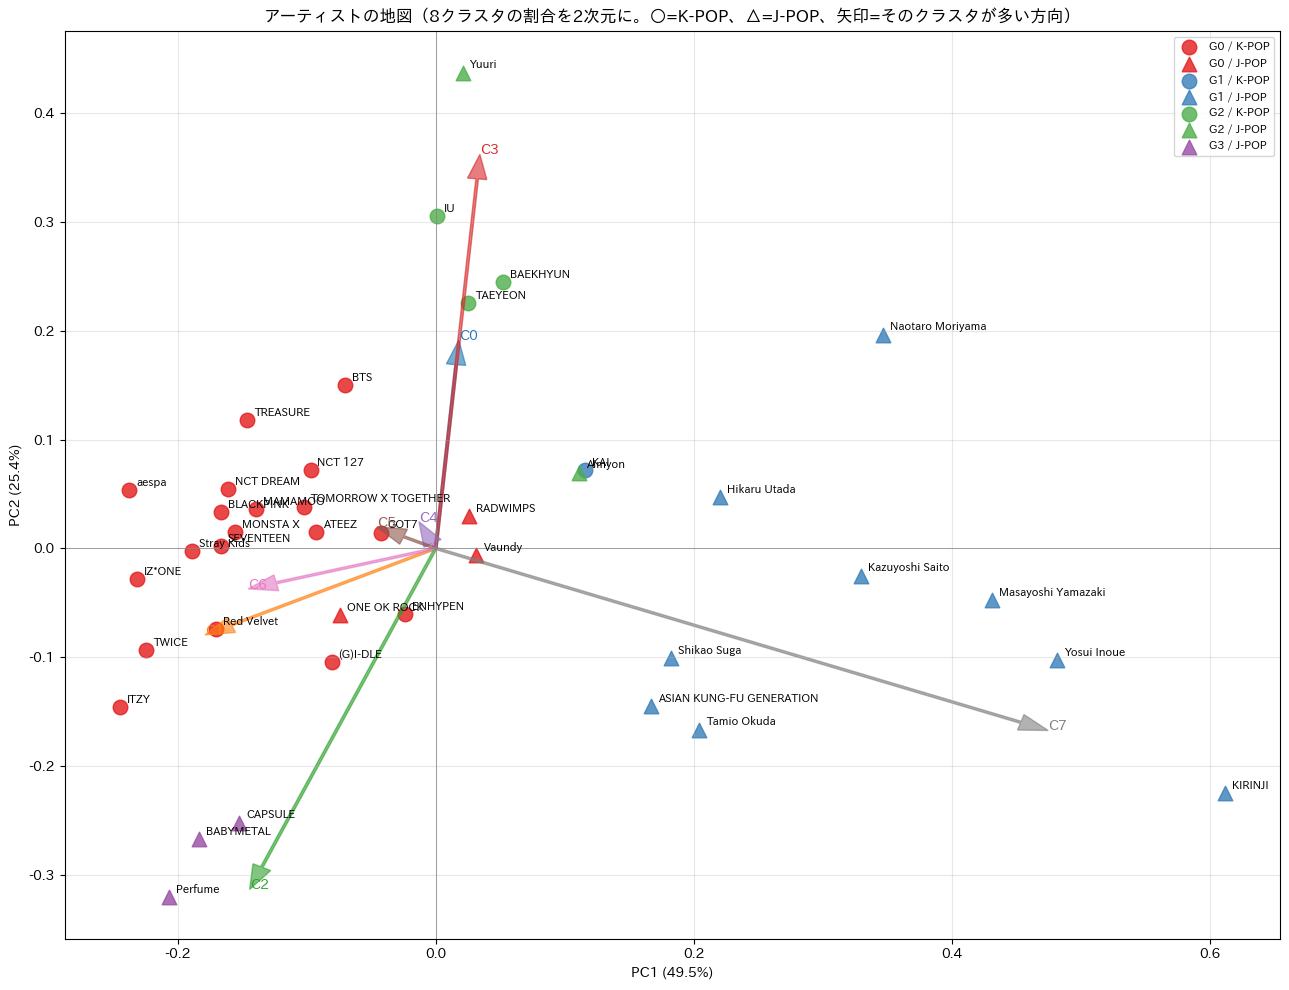


average cluster share: K-POP artists vs J-POP artists (%)
        C0    C1    C2    C3   C4    C5    C6    C7
J-POP  7.3  11.7  19.9  14.0  0.6   6.6   8.6  31.2
K-POP  7.7  21.7  16.5  16.3  2.9  13.0  15.5   6.3


In [158]:
# Step16: アーティストごとのクラスタの割合と、アーティストの地図（8次元 → 2次元）
# 必要な変数: multi, JPOP_ARTISTS（Step15）, KNOWN_BY_GENRE（Step11）, CHOSEN_K_V3

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

MIN_TRACKS = 10   # 割合を出す最低曲数
ART_GROUPS = 4    # アーティストのグループ数（地図を見て変えてよい）

targets = KNOWN_BY_GENRE['k-pop'] + JPOP_ARTISTS
t_lower = set(a.lower() for a in targets)
sub_m = multi[multi['artist_name'].str.lower().isin(t_lower)]
n_tr = sub_m.groupby('artist_name').size()
kept = n_tr[n_tr >= MIN_TRACKS].index
dropped = n_tr[n_tr < MIN_TRACKS]
sub_m = sub_m[sub_m['artist_name'].isin(kept)]
print(f"artists with >= {MIN_TRACKS} tracks: {len(kept)}")
print("excluded (too few tracks): " + ", ".join(f"{a}({n})" for a, n in dropped.items()))

cl_cols = [f'C{k}' for k in range(CHOSEN_K_V3)]
prop = pd.crosstab(sub_m['artist_name'], sub_m['cluster_v3'], normalize='index').reindex(columns=range(CHOSEN_K_V3), fill_value=0)
prop.columns = cl_cols
art_group = sub_m.groupby('artist_name')['group'].first().reindex(prop.index)
art_n = n_tr.reindex(prop.index)

# アーティストのグループ分け（割合が似ている人同士）
km_art = KMeans(n_clusters=ART_GROUPS, random_state=42, n_init=10)
art_cluster = pd.Series(km_art.fit_predict(prop.values), index=prop.index)

# 地図（8次元 → 2次元）
pca_art = PCA(n_components=2, random_state=42)
axy = pca_art.fit_transform(prop.values)
ev_a = pca_art.explained_variance_ratio_
print(f"PCA explained variance: PC1={ev_a[0]*100:.1f}%  PC2={ev_a[1]*100:.1f}%  (total {ev_a.sum()*100:.1f}%)")

# 表: アーティストごとの割合（%）
tbl = (prop * 100).round(1)
tbl.insert(0, 'tracks', art_n.values)
tbl.insert(0, 'art_group', [f'G{g}' for g in art_cluster.values])
tbl.insert(0, 'K/J', art_group.values)
tbl = tbl.sort_values(['art_group', 'K/J'])
print()
print("cluster share per artist (%)")
print(tbl.to_string())

# アーティストのグループの特徴（平均の割合）
print()
print("=== artist groups ===")
for g in range(ART_GROUPS):
    members = art_cluster[art_cluster == g].index.tolist()
    mean_p = prop.loc[members].mean().sort_values(ascending=False)
    top3 = ", ".join(f"{c}({v*100:.0f}%)" for c, v in mean_p.head(3).items())
    print(f"G{g} ({len(members)} artists): main clusters {top3}")
    print("    members: " + ", ".join(f"{m}[{art_group[m]}]" for m in members))

# 図1: 100%積み上げ棒グラフ
order = tbl.index
fig, ax = plt.subplots(figsize=(13, max(5, len(order) * 0.38)))
left = np.zeros(len(order))
for k, c in enumerate(cl_cols):
    vals = prop.loc[order, c].values
    ax.barh(range(len(order)), vals, left=left, color=plt.cm.tab10(k % 10), label=c)
    left += vals
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{a} [{art_group[a]}] G{art_cluster[a]} (n={art_n[a]})" for a in order], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('share of tracks')
ax.set_title(f"アーティストごとの曲のタイプの構成（k={CHOSEN_K_V3} のクラスタの割合）", fontsize=12, fontweight='bold')
ax.legend(ncol=CHOSEN_K_V3, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.savefig('step16_artist_share.png', dpi=150, bbox_inches='tight')
plt.show()

# 図2: アーティストの地図
fig, ax = plt.subplots(figsize=(13, 10))
markers = {'K-POP': 'o', 'J-POP': '^'}
for g in range(ART_GROUPS):
    for kj, mk in markers.items():
        m = ((art_cluster == g) & (art_group == kj)).values
        if m.sum() == 0:
            continue
        ax.scatter(axy[m, 0], axy[m, 1], s=110, marker=mk, color=plt.cm.Set1(g % 9), alpha=0.8, label=f'G{g} / {kj}')
for i, a in enumerate(prop.index):
    ax.annotate(a, (axy[i, 0], axy[i, 1]), fontsize=8, xytext=(5, 3), textcoords='offset points')
# 矢印: 各クラスタの割合が増える向き
scale = np.abs(axy).max() * 0.9
for k, c in enumerate(cl_cols):
    vx = pca_art.components_[0, k] * scale
    vy = pca_art.components_[1, k] * scale
    ax.arrow(0, 0, vx, vy, color=plt.cm.tab10(k % 10), alpha=0.6, width=0.002, head_width=0.015, length_includes_head=True)
    ax.annotate(c, (vx, vy), color=plt.cm.tab10(k % 10), fontsize=10, fontweight='bold')
ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)
ax.set_xlabel(f'PC1 ({ev_a[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({ev_a[1]*100:.1f}%)')
ax.set_title("アーティストの地図（8クラスタの割合を2次元に。○=K-POP、△=J-POP、矢印=そのクラスタが多い方向）", fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('step16_artist_map.png', dpi=150, bbox_inches='tight')
plt.show()

# K-POP と J-POP の平均構成
print()
print("average cluster share: K-POP artists vs J-POP artists (%)")
print((prop.groupby(art_group.values).mean() * 100).round(1).to_string())

#Step17: BTS の曲だけで見る

**打ち合わせメモ**: BTS の中だけで音楽的特徴で影響があるかは多少ある / SHAP の可視化 / BTS の曲で SHAP の図を作る

**(a)** 2020年 k-pop のモデルで、BTS の全曲（2013〜2022年）の SHAP 図を描く

**(b)** BTS の曲だけでモデルを作る。**アーティストを固定すれば、音楽的特徴で人気度の差を説明できるか**を確かめる
- 「年だけ」「音だけ」「音＋年」の3通りで、5分割の交差検証 R² を比べる（音を足すと年だけより良くなるか）
- 同じ曲の別バージョン（日本語版・リミックス）が学習側と評価側に分かれないよう、**曲名ごとに分割**する（GroupKFold）
- 「音＋年」のモデルの SHAP 図で、BTS の中で効いている特徴を見る

BTS: 245 tracks / 175 distinct songs / years 2013-2022
tracks per year: 2013:13, 2014:37, 2015:22, 2016:36, 2017:19, 2018:38, 2019:17, 2020:42, 2021:10, 2022:11


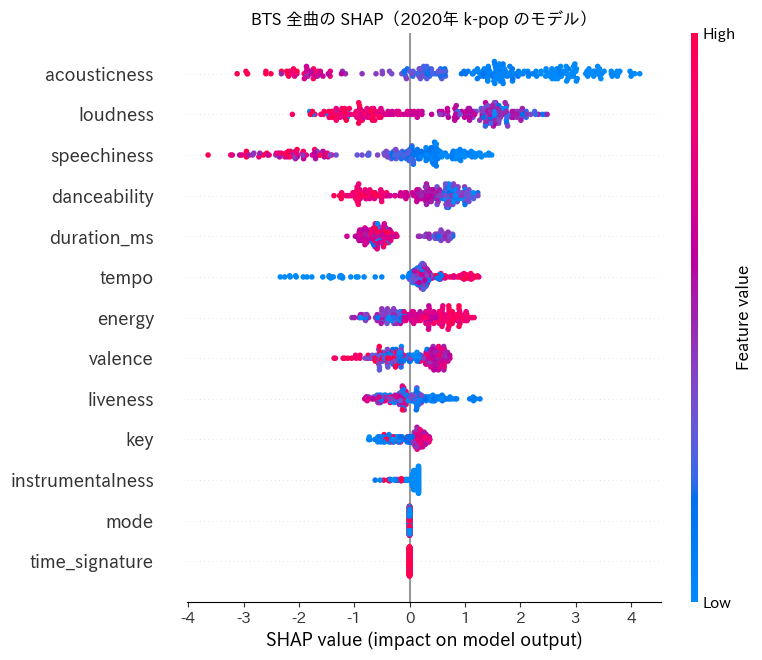


BTS only: 5-fold CV R2 (split by song, so versions of one song never sit on both sides)
    features      model  R2_mean  R2_sd
   year only GB (small)    0.013  0.053
   year only      Ridge    0.028  0.049
  music only GB (small)   -0.025  0.099
  music only      Ridge   -0.002  0.051
music + year GB (small)   -0.013  0.087
music + year      Ridge   -0.003  0.086


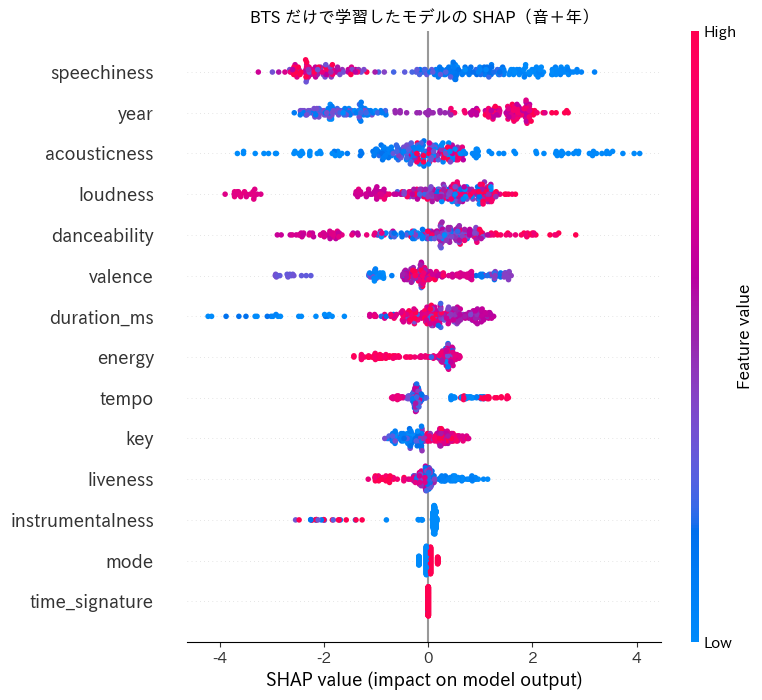

mean |SHAP| in the BTS-only model:
speechiness         1.54
year                1.53
acousticness        0.99
loudness            0.94
danceability        0.92
valence             0.71
duration_ms         0.69
energy              0.48
tempo               0.42
key                 0.35
liveness            0.30
instrumentalness    0.29
mode                0.07
time_signature      0.00


In [159]:
# Step17: BTS の曲だけで見る
# 必要な変数: df_clean, explainer_gb2, FEATURE_COLS_V2

from sklearn.model_selection import cross_val_score, GroupKFold
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

bts = df_clean[df_clean['artist_name'] == 'BTS'].drop_duplicates(subset='track_id').reset_index(drop=True)
titles_b = bts['track_name'].fillna('').astype(str)
bts['base_title'] = titles_b.str.split(' - ').str[0].str.split(' (', regex=False).str[0].str.strip().str.lower()
print(f"BTS: {len(bts)} tracks / {bts['base_title'].nunique()} distinct songs / years {int(bts['year'].min())}-{int(bts['year'].max())}")
print("tracks per year: " + ", ".join(f"{y}:{n}" for y, n in bts['year'].value_counts().sort_index().items()))

# (a) 2020年 k-pop のモデルで見た BTS の曲の SHAP 図
sv_bts = explainer_gb2(bts[FEATURE_COLS_V2], check_additivity=False)
shap.summary_plot(sv_bts, bts[FEATURE_COLS_V2], show=False)
plt.title("BTS 全曲の SHAP（2020年 k-pop のモデル）")
plt.tight_layout()
plt.savefig('step17_bts_shap_kpop_model.png', dpi=150, bbox_inches='tight')
plt.show()

# (b) BTS だけのモデル: 年だけ／音だけ／音＋年 を交差検証で比べる
FEATS_MY = FEATURE_COLS_V2 + ['year']
feature_sets = {'year only': ['year'], 'music only': FEATURE_COLS_V2, 'music + year': FEATS_MY}


def make_models():
    return {
        'GB (small)': HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, max_depth=3,
                                                    min_samples_leaf=20, l2_regularization=1.0, random_state=42),
        'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    }


gkf_b = GroupKFold(n_splits=5)
rows_b = []
for sname, cols in feature_sets.items():
    for mname, mdl in make_models().items():
        sc = cross_val_score(mdl, bts[cols], bts['popularity'],
                             cv=gkf_b.split(bts, bts['popularity'], bts['base_title']), scoring='r2')
        rows_b.append({'features': sname, 'model': mname, 'R2_mean': round(sc.mean(), 3), 'R2_sd': round(sc.std(), 3)})
print()
print("BTS only: 5-fold CV R2 (split by song, so versions of one song never sit on both sides)")
print(pd.DataFrame(rows_b).to_string(index=False))

# BTS だけのモデル（音＋年）の SHAP 図
gb_bts = make_models()['GB (small)']
gb_bts.fit(bts[FEATS_MY], bts['popularity'])
expl_bts = shap.Explainer(gb_bts, bts[FEATS_MY].sample(min(100, len(bts)), random_state=42))
sv_bts2 = expl_bts(bts[FEATS_MY], check_additivity=False)
shap.summary_plot(sv_bts2, bts[FEATS_MY], show=False)
plt.title("BTS だけで学習したモデルの SHAP（音＋年）")
plt.tight_layout()
plt.savefig('step17_bts_shap_bts_model.png', dpi=150, bbox_inches='tight')
plt.show()

imp_b = pd.Series(np.abs(sv_bts2.values).mean(axis=0), index=FEATS_MY).sort_values(ascending=False)
print("mean |SHAP| in the BTS-only model:")
print(imp_b.round(2).to_string())

#Step18: 人気度はアーティストでどこまで決まるか

**打ち合わせメモ**: アーティストそのものに依存 / 他の要素はノイズのようになってしまう

2020年の k-pop で学習し、2021年で評価する（これまでと同じ条件）。3つのモデルを比べる。

| モデル | 使う情報 |
|-------|---------|
| A | 音楽的特徴13個（これまでのモデル） |
| B | そのアーティストの2020年の平均人気度だけ |
| C | 音楽的特徴13個 ＋ アーティストの平均人気度 |

- 学習データでは、**自分の曲を除いた**アーティスト平均（leave-one-out）を使う。自分の人気度が答えに混ざるのを防ぐため
- 2020年に曲がないアーティストは、全体の平均で埋める
- 2021年の曲のうち「2020年にも曲があったアーティスト」に絞った結果も出す

**読み方**: B が A を大きく上回り、C が B とほぼ同じなら、「人気度はアーティストでほぼ決まり、音の情報を足しても上乗せにならない」と言える。

In [160]:
# Step18: 人気度はアーティストでどこまで決まるか（2020年で学習 → 2021年で評価）
# 必要な変数: df_2020, df_2021, FEATURE_COLS_V2

y20 = df_2020['popularity']
glob_mean = y20.mean()
grp20 = df_2020.groupby('artist_name')['popularity']
s20 = grp20.transform('sum')
n20 = grp20.transform('count')

tr = df_2020.copy()
# 学習データ: 自分の曲を除いた、そのアーティストの平均人気度（1曲だけのアーティストは全体平均）
tr['artist_pop'] = np.where(n20 > 1, (s20 - y20) / (n20 - 1).clip(lower=1), glob_mean)

te = df_2021.copy()
te['artist_pop'] = te['artist_name'].map(grp20.mean())
seen = te['artist_pop'].notna().values
te['artist_pop'] = te['artist_pop'].fillna(glob_mean)
print(f"2021 tracks: {len(te)} / artist also had tracks in 2020: {seen.sum()} ({seen.mean()*100:.1f}%)")

cases = {
    'A: music only': FEATURE_COLS_V2,
    'B: artist only': ['artist_pop'],
    'C: music + artist': FEATURE_COLS_V2 + ['artist_pop'],
}
rows_a = []
for name, cols in cases.items():
    mdl = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, max_depth=3,
                                        min_samples_leaf=50, l2_regularization=1.0, random_state=42)
    mdl.fit(tr[cols], tr['popularity'])
    pred = mdl.predict(te[cols])
    rows_a.append({
        'model': name,
        'R2_all_2021': round(r2_score(te['popularity'], pred), 3),
        'R2_seen_artists': round(r2_score(te['popularity'].values[seen], pred[seen]), 3),
        'MAE_all_2021': round(mean_absolute_error(te['popularity'], pred), 2),
    })
print()
print(pd.DataFrame(rows_a).to_string(index=False))
print()
print("seen artists = 2021 tracks whose artist also released tracks in 2020")

2021 tracks: 873 / artist also had tracks in 2020: 688 (78.8%)

            model  R2_all_2021  R2_seen_artists  MAE_all_2021
    A: music only       -0.036           -0.015          7.13
   B: artist only        0.282            0.337          5.80
C: music + artist        0.271            0.341          5.84

seen artists = 2021 tracks whose artist also released tracks in 2020


#Step19: J-POP の当てはめの確認

**目的**: Step15 で J-POP の曲を k-pop 2020年のクラスタに当てはめたところ、音が大きく激しいロックの ASIAN KUNG-FU GENERATION の曲の37%が「静かな生音・インスト系（C7）」に入った。J-POP への当てはめが信頼できるかを確かめる。

**方法**: 2つの決め方でクラスタを割り当て、どれだけ一致するかを比べる。
- **SHAP で決めたクラスタ**（Step15 の結果）: 「k-pop のモデルがその曲をどう読んだか」で決まる
- **音の数値で一番近いクラスタ**: 各クラスタの音の特徴の平均（k-pop 2020年で計算）に、曲の音の数値が一番近いクラスタ。key・mode・time_signature は番号や2値なので距離の計算から外す

**読み方**
- 一致率は、k-pop 2020年（モデルとクラスタを作った曲）でも100%にはならない（SHAP と音の数値は別の物差しのため）。**k-pop 2020年の一致率を基準**にする
- **J-POP の一致率が K-POP より大きく低い**なら、J-POP は「音の印象と合わないクラスタ」に入りやすく、J-POP の結果は参考にとどめるべき
- 「偶然の一致率」は、2つの決め方を無関係に割り当てた場合に一致する割合。一致率がこれに近いなら、2つの決め方はほぼ無関係

In [161]:
# Step19: J-POP の当てはめの確認（SHAP で決めたクラスタと、音の数値で一番近いクラスタの一致率）
# 必要な変数: df_2020（cluster_v3 付き）, multi（Step15）, JPOP_ARTISTS, FEATURE_COLS_V2, CHOSEN_K_V3

DIST_FEATS = [f for f in FEATURE_COLS_V2 if f not in ('key', 'mode', 'time_signature')]
mu = df_2020[DIST_FEATS].mean()
sd = df_2020[DIST_FEATS].std()

# 各クラスタの音の特徴の平均（k-pop 2020年で計算、zスコア）
cent = ((df_2020[DIST_FEATS] - mu) / sd).groupby(df_2020['cluster_v3'].values).mean()

# 全曲について、音の数値が一番近いクラスタを求める
Z = ((multi[DIST_FEATS] - mu) / sd).values
dist2 = ((Z[:, None, :] - cent.values[None, :, :]) ** 2).sum(axis=2)
multi['feat_cluster'] = cent.index.values[dist2.argmin(axis=1)]
multi['agree'] = multi['feat_cluster'] == multi['cluster_v3']


def chance_rate(sub):
    # 2つの決め方を無関係に割り当てた場合に一致する割合
    p = sub['cluster_v3'].value_counts(normalize=True)
    q = sub['feat_cluster'].value_counts(normalize=True)
    return float((p * q.reindex(p.index).fillna(0)).sum())


subsets = {
    'K-POP 2020 (base)': multi[(multi['group'] == 'K-POP') & (multi['year'] == 2020)],
    'K-POP other years': multi[(multi['group'] == 'K-POP') & (multi['year'] != 2020)],
    'J-POP': multi[multi['group'] == 'J-POP'],
}
rows19 = []
for name, sub in subsets.items():
    rows19.append({'subset': name, 'tracks': len(sub),
                   'agreement_%': round(sub['agree'].mean() * 100, 1),
                   'chance_%': round(chance_rate(sub) * 100, 1)})
print("Step19: SHAP cluster vs nearest cluster by musical features")
print("=" * 70)
print(pd.DataFrame(rows19).to_string(index=False))

# J-POP アーティストごとの一致率
print()
print("J-POP artists: agreement and main cluster by each method")
jrows = []
for a in JPOP_ARTISTS:
    d = multi[(multi['group'] == 'J-POP') & (multi['artist_name'].str.lower() == a.lower())]
    if len(d) < 10:
        continue
    jrows.append({'artist': a, 'tracks': len(d),
                  'agreement_%': round(d['agree'].mean() * 100, 1),
                  'main_by_SHAP': 'C' + str(d['cluster_v3'].value_counts().index[0]),
                  'main_by_features': 'C' + str(d['feat_cluster'].value_counts().index[0]),
                  'C7_by_SHAP_%': round((d['cluster_v3'] == 7).mean() * 100, 1),
                  'C7_by_features_%': round((d['feat_cluster'] == 7).mean() * 100, 1)})
print(pd.DataFrame(jrows).sort_values('agreement_%').to_string(index=False))

# J-POP 全体のクラスタの割合: 2つの決め方で比べる
cl_cols = [f'C{k}' for k in range(CHOSEN_K_V3)]
jp_all = subsets['J-POP']
comp = pd.DataFrame({
    'by SHAP (%)': jp_all['cluster_v3'].value_counts(normalize=True).reindex(range(CHOSEN_K_V3), fill_value=0).values * 100,
    'by features (%)': jp_all['feat_cluster'].value_counts(normalize=True).reindex(range(CHOSEN_K_V3), fill_value=0).values * 100,
}, index=cl_cols).round(1)
print()
print("J-POP: cluster share by each method (%)")
print(comp.T.to_string())

# ASIAN KUNG-FU GENERATION: SHAP で決めたクラスタ（行）と音の数値で一番近いクラスタ（列）
akfg = multi[multi['artist_name'] == 'ASIAN KUNG-FU GENERATION']
print()
print("ASIAN KUNG-FU GENERATION: rows = cluster by SHAP, columns = nearest cluster by features")
print(pd.crosstab(akfg['cluster_v3'], akfg['feat_cluster']).to_string())

# AKFG で C7 に入った曲の音の特徴と、k-pop の C7 の平均（zスコア）
akfg_c7 = akfg[akfg['cluster_v3'] == 7]
if len(akfg_c7) > 0:
    zc = pd.DataFrame({
        'k-pop C7 mean': cent.loc[7],
        'AKFG tracks in C7': ((akfg_c7[DIST_FEATS] - mu) / sd).mean(),
    }).round(2)
    print()
    print("musical features (z-score, 0 = k-pop 2020 average)")
    print(zc.to_string())

Step19: SHAP cluster vs nearest cluster by musical features
           subset  tracks  agreement_%  chance_%
K-POP 2020 (base)     820         49.5      13.7
K-POP other years    3421         46.3      13.4
            J-POP    1386         34.2      15.1

J-POP artists: agreement and main cluster by each method
                  artist  tracks  agreement_% main_by_SHAP main_by_features  C7_by_SHAP_%  C7_by_features_%
               BABYMETAL      48         16.7           C2               C6           8.3              25.0
                 Perfume      81         23.5           C2               C1           6.2              13.6
             Shikao Suga      72         25.0           C7               C1          34.7               8.3
                 KIRINJI      66         27.3           C7               C3          77.3              27.3
ASIAN KUNG-FU GENERATION     156         27.6           C7               C6          37.2              17.3
                 CAPSULE     126      